# Handwritten Digits Recognition

## Project ID: PRCP-1002

### Objective

The objective of this project is to classify handwritten digit images into one of the 10 classes representing digits from 0 to 9.

The project includes:

- Data analysis
- Data visualization
- Data preprocessing
- Building multiple machine learning models
- Comparing model performance
- Selecting the best model
- Identifying challenges faced during the project

### Developed By - Sindhu S

In [1]:
# Importing Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.datasets import mnist

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
# Loading the MNIST Dataset

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("MNIST Dataset Loaded Successfully")

MNIST Dataset Loaded Successfully


In [3]:
# Checking Training and Testing Data

print("Training Images Shape:", x_train.shape)
print("Training Labels Shape:", y_train.shape)

print()

print("Testing Images Shape:", x_test.shape)
print("Testing Labels Shape:", y_test.shape)

Training Images Shape: (60000, 28, 28)
Training Labels Shape: (60000,)

Testing Images Shape: (10000, 28, 28)
Testing Labels Shape: (10000,)


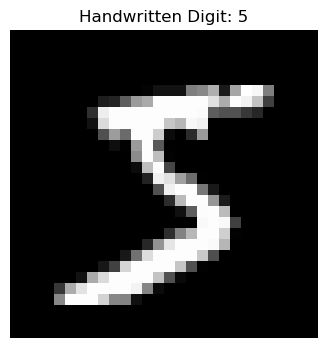

In [4]:
# Displaying the First Handwritten Digit

plt.figure(figsize=(4, 4))

plt.imshow(x_train[0], cmap="gray")

plt.title(f"Handwritten Digit: {y_train[0]}")

plt.axis("off")

plt.show()

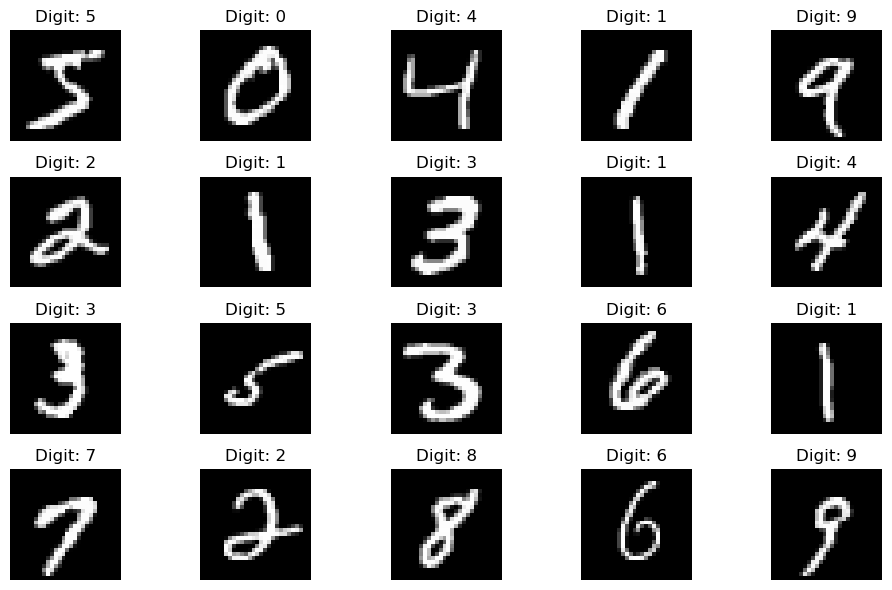

In [5]:
# Displaying Multiple Handwritten Digits

plt.figure(figsize=(10, 6))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()

plt.show()

In [6]:
# Checking Minimum and Maximum Pixel Values

print("Minimum Pixel Value:", x_train.min())
print("Maximum Pixel Value:", x_train.max())

Minimum Pixel Value: 0
Maximum Pixel Value: 255


In [7]:
# Checking Distribution of Digit Classes

unique, counts = np.unique(y_train, return_counts=True)

digit_distribution = pd.DataFrame({
    "Digit": unique,
    "Count": counts
})

print(digit_distribution)

   Digit  Count
0      0   5923
1      1   6742
2      2   5958
3      3   6131
4      4   5842
5      5   5421
6      6   5918
7      7   6265
8      8   5851
9      9   5949


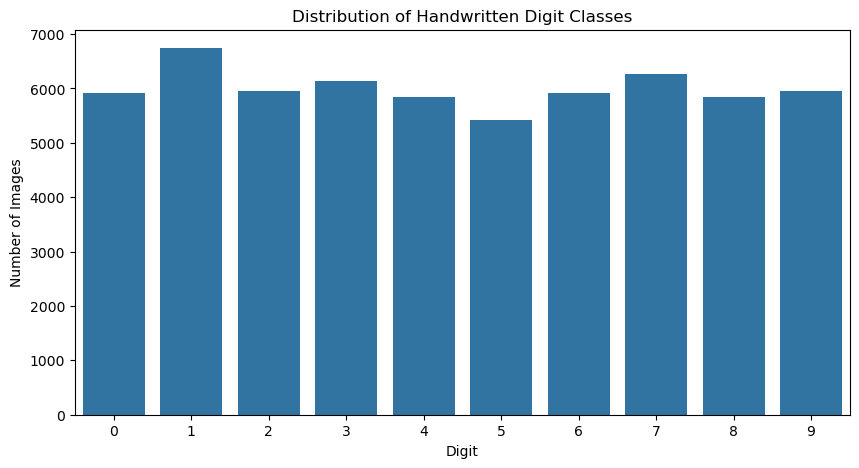

In [8]:
# Visualizing Digit Class Distribution

plt.figure(figsize=(10, 5))

sns.barplot(x="Digit", y="Count", data=digit_distribution)

plt.title("Distribution of Handwritten Digit Classes")

plt.xlabel("Digit")

plt.ylabel("Number of Images")

plt.show()

In [9]:
# Checking for Missing Values

print("Missing Values in Training Images:", np.isnan(x_train).sum())
print("Missing Values in Testing Images:", np.isnan(x_test).sum())
print("Missing Values in Training Labels:", np.isnan(y_train).sum())
print("Missing Values in Testing Labels:", np.isnan(y_test).sum())

Missing Values in Training Images: 0
Missing Values in Testing Images: 0
Missing Values in Training Labels: 0
Missing Values in Testing Labels: 0


In [10]:
# Checking Image Dimensions

print("Image Height:", x_train.shape[1])
print("Image Width:", x_train.shape[2])

print("Total Pixels Per Image:", x_train.shape[1] * x_train.shape[2])

Image Height: 28
Image Width: 28
Total Pixels Per Image: 784


In [11]:
# Creating Dataset Summary

dataset_summary = pd.DataFrame({
    "Property": [
        "Training Images",
        "Testing Images",
        "Image Height",
        "Image Width",
        "Pixels Per Image",
        "Number of Classes",
        "Minimum Pixel Value",
        "Maximum Pixel Value"
    ],
    
    "Value": [
        x_train.shape[0],
        x_test.shape[0],
        x_train.shape[1],
        x_train.shape[2],
        x_train.shape[1] * x_train.shape[2],
        len(np.unique(y_train)),
        x_train.min(),
        x_train.max()
    ]
})

dataset_summary

,Property,Value
0,Training Images,60000
1,Testing Images,10000
2,Image Height,28
3,Image Width,28
4,Pixels Per Image,784
5,Number of Classes,10
6,Minimum Pixel Value,0
7,Maximum Pixel Value,255


## Data Analysis Findings

The MNIST dataset contains handwritten digit images belonging to 10 different classes, representing the digits from 0 to 9.

The training dataset contains 60,000 images and the testing dataset contains 10,000 images.

Each image has dimensions of 28 × 28 pixels, resulting in 784 pixels per image.

The pixel values range from 0 to 255.

The dataset contains the digit classes 0 through 9.

The digit class distribution was visualized to understand the number of images available for each class.

No missing values were identified in the training or testing images and labels.

In [12]:
# Comparing Training and Testing Class Distribution

train_unique, train_counts = np.unique(y_train, return_counts=True)
test_unique, test_counts = np.unique(y_test, return_counts=True)

class_distribution = pd.DataFrame({
    "Digit": train_unique,
    "Training Count": train_counts,
    "Testing Count": test_counts
})

class_distribution

,Digit,Training Count,Testing Count
0,0,5923,980
1,1,6742,1135
2,2,5958,1032
3,3,6131,1010
4,4,5842,982
5,5,5421,892
6,6,5918,958
7,7,6265,1028
8,8,5851,974
9,9,5949,1009


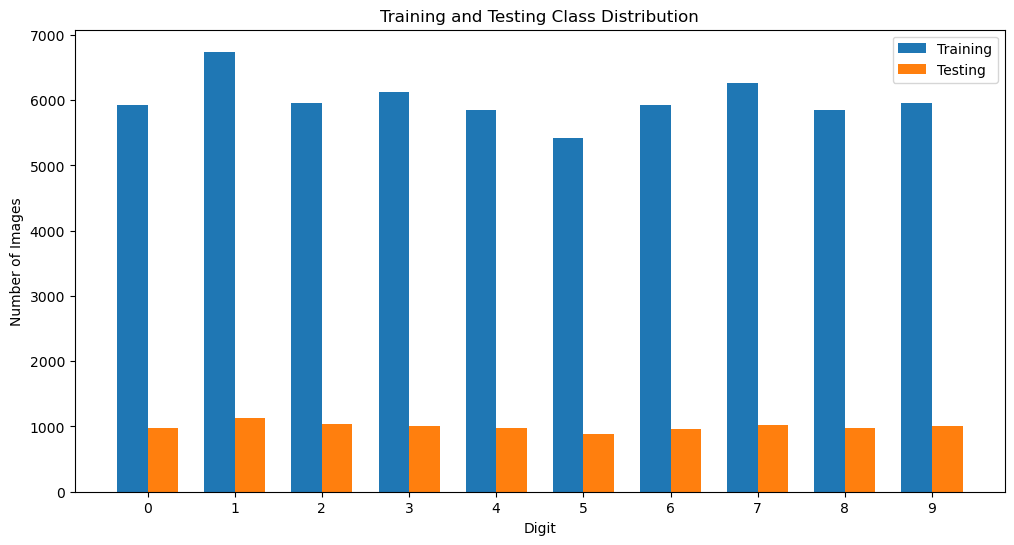

In [13]:
# Visualizing Training and Testing Class Distribution

x = np.arange(10)
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(x - width / 2, train_counts, width, label="Training")
plt.bar(x + width / 2, test_counts, width, label="Testing")

plt.title("Training and Testing Class Distribution")
plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.xticks(x)
plt.legend()

plt.show()

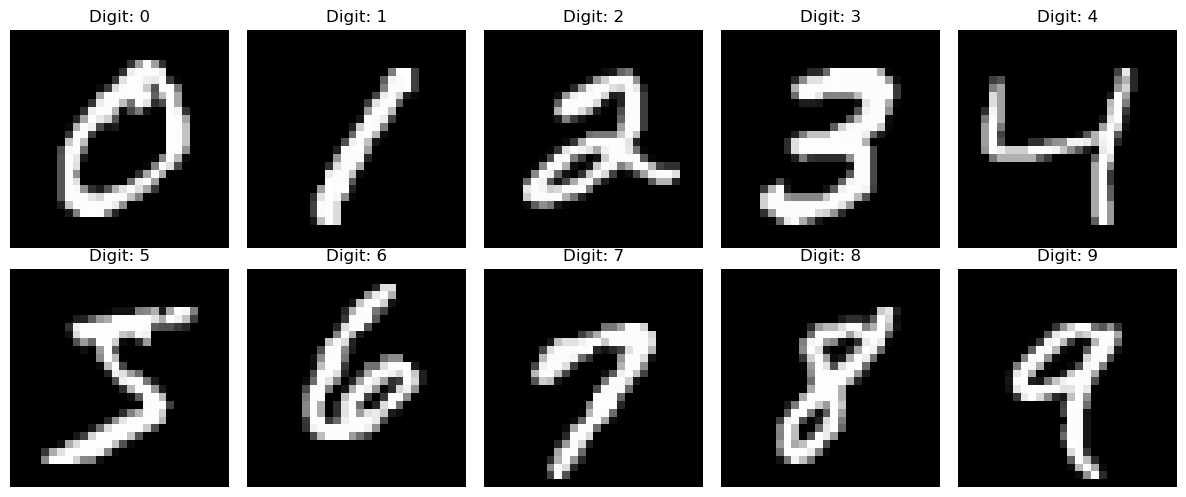

In [14]:
# Displaying One Example of Each Digit

plt.figure(figsize=(12, 5))

for digit in range(10):
    index = np.where(y_train == digit)[0][0]
    
    plt.subplot(2, 5, digit + 1)
    plt.imshow(x_train[index], cmap="gray")
    plt.title(f"Digit: {digit}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
# Calculating Average Image for Each Digit

average_images = []

for digit in range(10):
    digit_images = x_train[y_train == digit]
    average_image = digit_images.mean(axis=0)
    average_images.append(average_image)

average_images = np.array(average_images)

print("Average Images Shape:", average_images.shape)

Average Images Shape: (10, 28, 28)


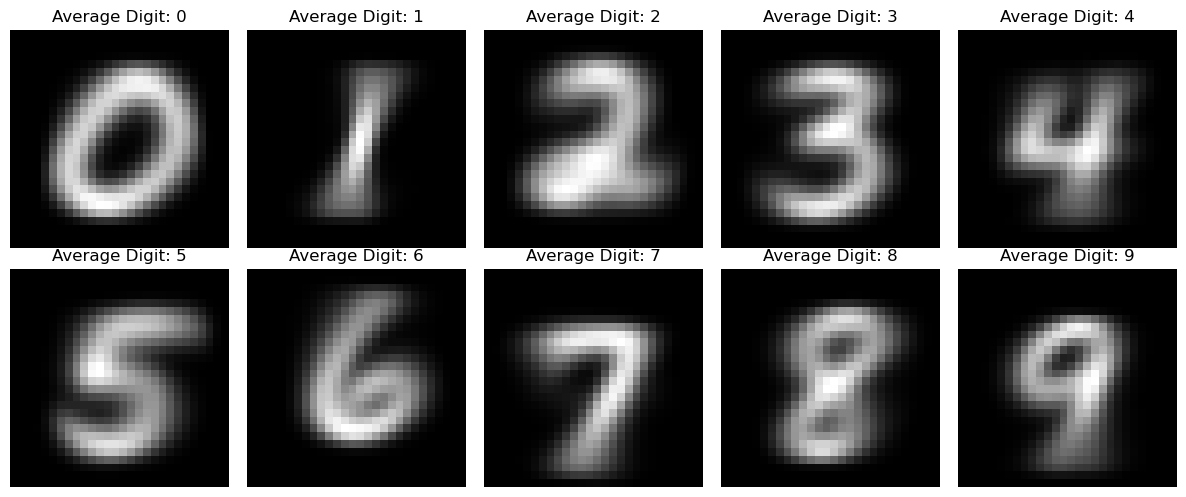

In [16]:
# Visualizing Average Image for Each Digit

plt.figure(figsize=(12, 5))

for digit in range(10):
    plt.subplot(2, 5, digit + 1)
    plt.imshow(average_images[digit], cmap="gray")
    plt.title(f"Average Digit: {digit}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Analyzing Pixel Intensity Distribution

pixel_values = x_train.flatten()

print("Minimum Pixel Value:", pixel_values.min())
print("Maximum Pixel Value:", pixel_values.max())
print("Mean Pixel Value:", pixel_values.mean())
print("Median Pixel Value:", np.median(pixel_values))

Minimum Pixel Value: 0
Maximum Pixel Value: 255
Mean Pixel Value: 33.318421449829934
Median Pixel Value: 0.0


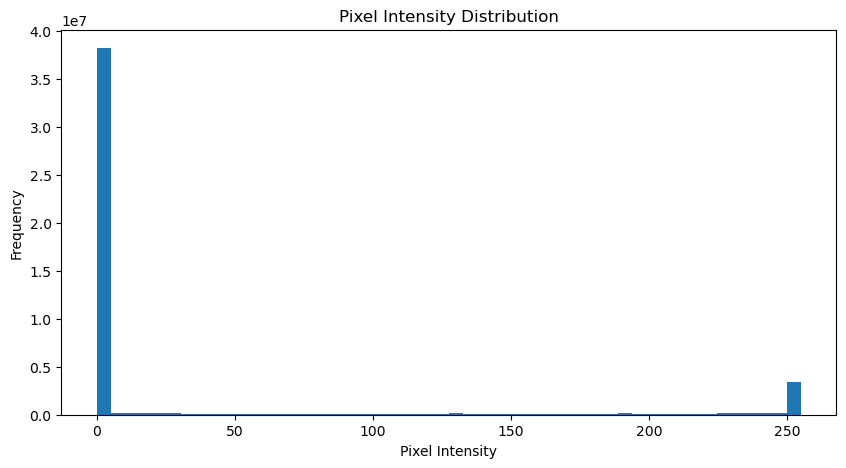

In [18]:
# Visualizing Pixel Intensity Distribution

plt.figure(figsize=(10, 5))

plt.hist(pixel_values, bins=50)

plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

In [19]:
# Calculating Mean Pixel Intensity by Digit

mean_intensity_by_digit = []

for digit in range(10):
    digit_images = x_train[y_train == digit]
    mean_intensity = digit_images.mean()
    mean_intensity_by_digit.append(mean_intensity)

mean_intensity_df = pd.DataFrame({
    "Digit": range(10),
    "Mean Pixel Intensity": mean_intensity_by_digit
})

mean_intensity_df

,Digit,Mean Pixel Intensity
0,0,44.216828
1,1,19.379654
2,2,37.988658
3,3,36.090187
4,4,30.948226
5,5,32.831095
6,6,35.011953
7,7,29.204563
8,8,38.289775
9,9,31.260435


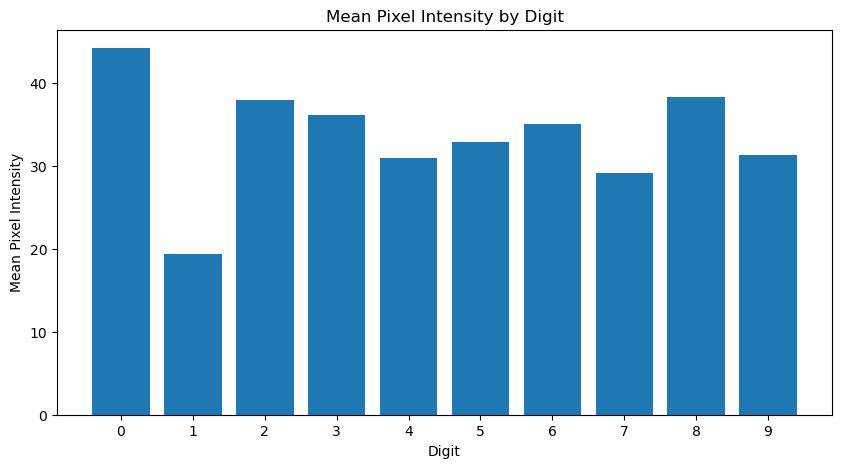

In [20]:
# Visualizing Mean Pixel Intensity by Digit

plt.figure(figsize=(10, 5))

plt.bar(
    mean_intensity_df["Digit"],
    mean_intensity_df["Mean Pixel Intensity"]
)

plt.title("Mean Pixel Intensity by Digit")
plt.xlabel("Digit")
plt.ylabel("Mean Pixel Intensity")
plt.xticks(range(10))

plt.show()

In [21]:
# Analyzing Non-Zero Pixels

non_zero_pixels = np.count_nonzero(x_train, axis=(1, 2))

print("Average Non-Zero Pixels Per Image:", non_zero_pixels.mean())
print("Minimum Non-Zero Pixels:", non_zero_pixels.min())
print("Maximum Non-Zero Pixels:", non_zero_pixels.max())

Average Non-Zero Pixels Per Image: 149.9026
Minimum Non-Zero Pixels: 34
Maximum Non-Zero Pixels: 351


## Exploratory Data Analysis Findings

The training and testing datasets were compared based on the distribution of the ten digit classes.

Sample images from all ten classes were visualized to understand the variation in handwritten digits.

Average images were calculated for each digit class to identify common pixel patterns within each class.

The pixel intensity distribution was analyzed to understand the numerical representation of the grayscale images.

The mean pixel intensity for each digit was also examined.

The number of non-zero pixels in the images was analyzed to understand the amount of image information present compared with the background.

In [22]:
# Flattening the Image Data

x_train_flat = x_train.reshape(x_train.shape[0], -1)
x_test_flat = x_test.reshape(x_test.shape[0], -1)

print("Training Data Shape:", x_train_flat.shape)
print("Testing Data Shape:", x_test_flat.shape)

Training Data Shape: (60000, 784)
Testing Data Shape: (10000, 784)


In [23]:
# Checking Flattened Image Data

print("Original Image Shape:", x_train[0].shape)
print("Flattened Image Shape:", x_train_flat[0].shape)

print()

Original Image Shape: (28, 28)
Flattened Image Shape: (784,)



In [24]:
# Normalizing Pixel Values

x_train_scaled = x_train_flat.astype("float32") / 255.0
x_test_scaled = x_test_flat.astype("float32") / 255.0

print("Minimum Training Pixel Value:", x_train_scaled.min())
print("Maximum Training Pixel Value:", x_train_scaled.max())

print("Minimum Testing Pixel Value:", x_test_scaled.min())
print("Maximum Testing Pixel Value:", x_test_scaled.max())

Minimum Training Pixel Value: 0.0
Maximum Training Pixel Value: 1.0
Minimum Testing Pixel Value: 0.0
Maximum Testing Pixel Value: 1.0


In [25]:
# Checking Shape of Preprocessed Data

print("Preprocessed Training Data Shape:", x_train_scaled.shape)
print("Preprocessed Testing Data Shape:", x_test_scaled.shape)

print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

Preprocessed Training Data Shape: (60000, 784)
Preprocessed Testing Data Shape: (10000, 784)
Training Labels Shape: (60000,)
Testing Labels Shape: (10000,)


In [26]:
# Checking for Missing Values After Preprocessing

print("Missing Values in Training Data:", np.isnan(x_train_scaled).sum())
print("Missing Values in Testing Data:", np.isnan(x_test_scaled).sum())

Missing Values in Training Data: 0
Missing Values in Testing Data: 0


In [27]:
# Checking Data Type After Preprocessing

print("Training Data Type:", x_train_scaled.dtype)
print("Testing Data Type:", x_test_scaled.dtype)

Training Data Type: float32
Testing Data Type: float32


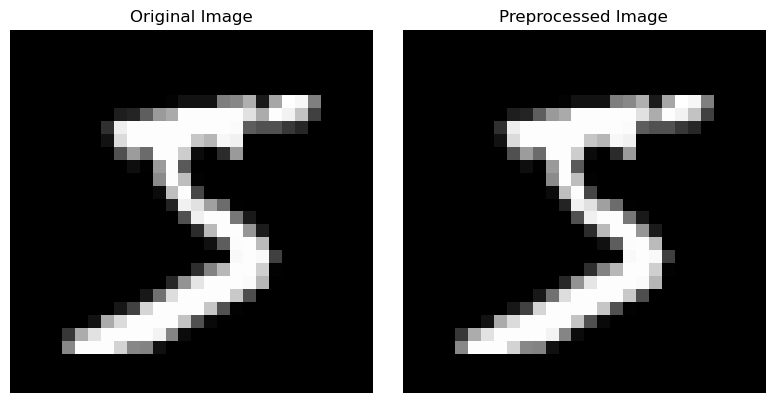

In [28]:
# Verifying Image After Preprocessing

original_image = x_train[0]
processed_image = x_train_scaled[0].reshape(28, 28)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_image, cmap="gray")
plt.title("Preprocessed Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [29]:
# Creating Preprocessing Summary

preprocessing_summary = pd.DataFrame({
    "Property": [
        "Original Image Size",
        "Features Per Image",
        "Training Samples",
        "Testing Samples",
        "Original Pixel Range",
        "Preprocessed Pixel Range",
        "Training Data Shape",
        "Testing Data Shape"
    ],
    
    "Before Preprocessing": [
        "28 × 28",
        784,
        60000,
        10000,
        "0–255",
        "Not Applicable",
        "(60000, 28, 28)",
        "(10000, 28, 28)"
    ],
    
    "After Preprocessing": [
        "Flattened",
        784,
        60000,
        10000,
        "0–255",
        "0–1",
        "(60000, 784)",
        "(10000, 784)"
    ]
})

preprocessing_summary

,Property,Before Preprocessing,After Preprocessing
0,Original Image Size,28 × 28,Flattened
1,Features Per Image,784,784
2,Training Samples,60000,60000
3,Testing Samples,10000,10000
4,Original Pixel Range,0–255,0–255
5,Preprocessed Pixel Range,Not Applicable,0–1
6,Training Data Shape,"(60000, 28, 28)","(60000, 784)"
7,Testing Data Shape,"(10000, 28, 28)","(10000, 784)"


## Data Preprocessing

The MNIST image data was prepared for machine learning classification.

The original images have dimensions of 28 × 28 pixels. Each image was flattened into a one-dimensional array containing 784 features.

The pixel values originally ranged from 0 to 255. The pixel values were normalized by dividing them by 255, resulting in a range from 0 to 1.

The training and testing datasets were kept separate during preprocessing.

Missing-value checks were also performed after preprocessing, and no missing values were found.

The preprocessed data is now ready for machine learning model development.

In [30]:
# Creating Training and Validation Sets

from sklearn.model_selection import train_test_split

X_train, X_validation, y_train_model, y_validation = train_test_split(
    x_train_scaled,
    y_train,
    test_size=0.1667,
    random_state=42,
    stratify=y_train
)

print("Training Data Shape:", X_train.shape)
print("Validation Data Shape:", X_validation.shape)
print("Training Labels Shape:", y_train_model.shape)
print("Validation Labels Shape:", y_validation.shape)

Training Data Shape: (49998, 784)
Validation Data Shape: (10002, 784)
Training Labels Shape: (49998,)
Validation Labels Shape: (10002,)


In [31]:
# Checking Validation Class Distribution

validation_unique, validation_counts = np.unique(
    y_validation,
    return_counts=True
)

validation_distribution = pd.DataFrame({
    "Digit": validation_unique,
    "Validation Count": validation_counts
})

validation_distribution

,Digit,Validation Count
0,0,987
1,1,1124
2,2,993
3,3,1022
4,4,974
5,5,904
6,6,987
7,7,1044
8,8,975
9,9,992


In [32]:
# Comparing Training and Validation Class Distribution

train_model_unique, train_model_counts = np.unique(
    y_train_model,
    return_counts=True
)

comparison_distribution = pd.DataFrame({
    "Digit": train_model_unique,
    "Training Count": train_model_counts,
    "Validation Count": validation_counts
})

comparison_distribution

,Digit,Training Count,Validation Count
0,0,4936,987
1,1,5618,1124
2,2,4965,993
3,3,5109,1022
4,4,4868,974
5,5,4517,904
6,6,4931,987
7,7,5221,1044
8,8,4876,975
9,9,4957,992


In [33]:
# Creating Model Performance Storage

model_results = []

print("Model performance storage created successfully")

Model performance storage created successfully


In [34]:
# Importing Model Evaluation Metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Evaluation metrics imported successfully")

Evaluation metrics imported successfully


## Model Evaluation Metrics

The classification models will be evaluated using multiple performance metrics.

### Accuracy

Accuracy measures the proportion of correctly classified images among all evaluated images.

### Precision

Precision measures how many of the images predicted as a particular class actually belong to that class.

### Recall

Recall measures how many of the actual images belonging to a class were correctly identified.

### F1 Score

F1 score combines precision and recall into a single metric.

### Confusion Matrix

A confusion matrix will be used to understand which digit classes are being correctly classified and which classes are being confused with one another.

These metrics will be used together when comparing the classification models.

# Model Comparison Report

## Model Performance Comparison

Four classification models were evaluated for handwritten digit recognition:

- Logistic Regression
- K-Nearest Neighbors
- Support Vector Machine
- Random Forest

The models were evaluated on the same validation dataset using Accuracy, Precision, Recall, and F1 Score.

The model comparison showed that K-Nearest Neighbors achieved the highest validation performance among the evaluated models.

The KNN model achieved a validation accuracy of approximately 97.20%.

## Final Model Selection

Based on the validation results and subsequent hyperparameter tuning, K-Nearest Neighbors with 3 neighbors and distance weighting was selected for final evaluation.

The selected configuration achieved:

- Validation Accuracy: 97.20%
- Test Accuracy: 97.00%
- Test Precision: 97.01%
- Test Recall: 97.00%
- Test F1 Score: 97.00%

## Production Recommendation

For this project, the tuned K-Nearest Neighbors model is recommended as the production candidate because it achieved the highest validation performance among the evaluated models and was successfully verified after saving and reloading the model.

The final model was saved as:

`final_knn_model.pkl`

The model was also tested through a reusable prediction function to verify that it can generate digit predictions after being loaded from the saved model file.

## Model Comparison Conclusion

The model comparison demonstrated that different classification algorithms produced different levels of performance on the handwritten digit recognition task.

K-Nearest Neighbors was selected based on the validation results and was subsequently evaluated on the separate test dataset.

In [35]:
# Importing Logistic Regression

from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully")

Logistic Regression imported successfully


In [36]:
# Creating the Logistic Regression Model

logistic_model = LogisticRegression(
    max_iter=100,
    solver="lbfgs"
)

print("Logistic Regression model created successfully")

Logistic Regression model created successfully


In [37]:
# Training the Logistic Regression Model

logistic_model.fit(X_train, y_train_model)

print("Logistic Regression model training completed")

Logistic Regression model training completed


In [38]:
# Making Predictions Using Logistic Regression

y_pred_logistic = logistic_model.predict(X_validation)

print("Predictions generated successfully")
print("Number of Predictions:", len(y_pred_logistic))

Predictions generated successfully
Number of Predictions: 10002


In [39]:
# Calculating Logistic Regression Accuracy

logistic_accuracy = accuracy_score(
    y_validation,
    y_pred_logistic
)

print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.9212157568486303


In [40]:
# Calculating Logistic Regression Performance Metrics

logistic_precision = precision_score(
    y_validation,
    y_pred_logistic,
    average="weighted"
)

logistic_recall = recall_score(
    y_validation,
    y_pred_logistic,
    average="weighted"
)

logistic_f1 = f1_score(
    y_validation,
    y_pred_logistic,
    average="weighted"
)

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1 Score :", logistic_f1)

Logistic Regression Performance
--------------------------------
Accuracy : 0.9212157568486303
Precision: 0.9211610907295109
Recall   : 0.9212157568486303
F1 Score : 0.9211293875998448


In [41]:
# Classification Report for Logistic Regression

print(
    classification_report(
        y_validation,
        y_pred_logistic
    )
)

              precision    recall  f1-score   support

           0       0.95      0.97      0.96       987
           1       0.95      0.97      0.96      1124
           2       0.91      0.89      0.90       993
           3       0.90      0.89      0.90      1022
           4       0.94      0.93      0.94       974
           5       0.88      0.88      0.88       904
           6       0.95      0.95      0.95       987
           7       0.94      0.93      0.93      1044
           8       0.87      0.88      0.87       975
           9       0.90      0.92      0.91       992

    accuracy                           0.92     10002
   macro avg       0.92      0.92      0.92     10002
weighted avg       0.92      0.92      0.92     10002



In [42]:
# Creating Confusion Matrix for Logistic Regression

logistic_cm = confusion_matrix(
    y_validation,
    y_pred_logistic
)

print(logistic_cm)

[[ 954    0    1    1    1   12    8    2    5    3]
 [   0 1093    9    4    1    2    0    1   10    4]
 [   6   13  888   19    9    4   15    5   30    4]
 [   4    4   26  908    1   32    1    9   29    8]
 [   3    2    6    1  909    0    8    5    6   34]
 [  11    3    8   26   11  791   11    5   31    7]
 [   7    2    6    1    7   20  937    0    6    1]
 [   2    5   13    5   11    2    0  967    4   35]
 [   9   20   14   32    3   25    7    2  855    8]
 [   3    8    0    8   15    7    1   31    7  912]]


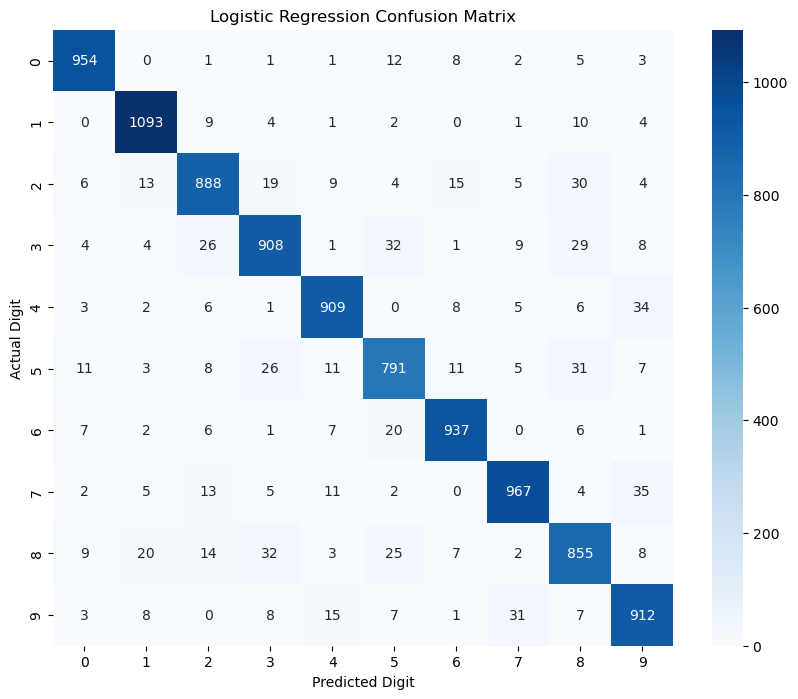

In [43]:
# Visualizing Logistic Regression Confusion Matrix

plt.figure(figsize=(10, 8))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted Digit")

plt.ylabel("Actual Digit")

plt.show()

In [44]:
# Storing Logistic Regression Results

model_results.append({
    "Model": "Logistic Regression",
    "Accuracy": logistic_accuracy,
    "Precision": logistic_precision,
    "Recall": logistic_recall,
    "F1 Score": logistic_f1
})

print("Logistic Regression results stored successfully")

Logistic Regression results stored successfully


## Logistic Regression Model Analysis

Logistic Regression was implemented as the first classification model for the handwritten digit recognition task.

The model was trained using the preprocessed training dataset and evaluated using the validation dataset.

Accuracy, precision, recall, and F1 score were calculated to measure the classification performance.

A classification report was generated to examine the performance for individual digit classes.

A confusion matrix was also created to identify correct classifications and instances where handwritten digits were confused with other classes.

The Logistic Regression results will be compared with other classification models later in the project.

In [45]:
# Importing K-Nearest Neighbors

from sklearn.neighbors import KNeighborsClassifier

print("KNN imported successfully")

KNN imported successfully


In [46]:
# Creating the KNN Model

knn_model = KNeighborsClassifier(
    n_neighbors=3,
    weights="distance",
    n_jobs=-1
)

print("KNN model created successfully")

KNN model created successfully


In [47]:
# Training the KNN Model

knn_model.fit(X_train, y_train_model)

print("KNN model training completed")

KNN model training completed


In [48]:
# Making Predictions Using KNN

y_pred_knn = knn_model.predict(X_validation)

print("KNN predictions generated successfully")
print("Number of Predictions:", len(y_pred_knn))

KNN predictions generated successfully
Number of Predictions: 10002


In [49]:
# Calculating KNN Accuracy

knn_accuracy = accuracy_score(
    y_validation,
    y_pred_knn
)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.972005598880224


In [50]:
# Calculating KNN Performance Metrics

knn_precision = precision_score(
    y_validation,
    y_pred_knn,
    average="weighted"
)

knn_recall = recall_score(
    y_validation,
    y_pred_knn,
    average="weighted"
)

knn_f1 = f1_score(
    y_validation,
    y_pred_knn,
    average="weighted"
)

print("KNN Performance")
print("----------------")
print("Accuracy :", knn_accuracy)
print("Precision:", knn_precision)
print("Recall   :", knn_recall)
print("F1 Score :", knn_f1)

KNN Performance
----------------
Accuracy : 0.972005598880224
Precision: 0.9722004095905827
Recall   : 0.972005598880224
F1 Score : 0.971970760963947


In [51]:
# Classification Report for KNN

print(
    classification_report(
        y_validation,
        y_pred_knn
    )
)

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       987
           1       0.95      0.99      0.97      1124
           2       0.98      0.97      0.98       993
           3       0.97      0.96      0.97      1022
           4       0.98      0.97      0.98       974
           5       0.97      0.96      0.97       904
           6       0.99      0.98      0.99       987
           7       0.97      0.97      0.97      1044
           8       0.98      0.94      0.96       975
           9       0.96      0.97      0.96       992

    accuracy                           0.97     10002
   macro avg       0.97      0.97      0.97     10002
weighted avg       0.97      0.97      0.97     10002



In [52]:
# Creating Confusion Matrix for KNN

knn_cm = confusion_matrix(
    y_validation,
    y_pred_knn
)

print(knn_cm)

[[ 985    1    0    0    0    0    1    0    0    0]
 [   0 1118    2    0    0    1    0    2    0    1]
 [   5    9  964    3    0    1    0    9    2    0]
 [   1    2    6  986    0   11    1    3    9    3]
 [   0    5    1    1  947    0    0    3    0   17]
 [   2    2    0   12    2  871    8    0    3    4]
 [   6    5    0    0    1    4  970    0    1    0]
 [   0   15    5    0    5    0    0 1009    2    8]
 [   3   18    5   14    3    7    2    0  912   11]
 [   2    5    1    2    9    2    0    9    2  960]]


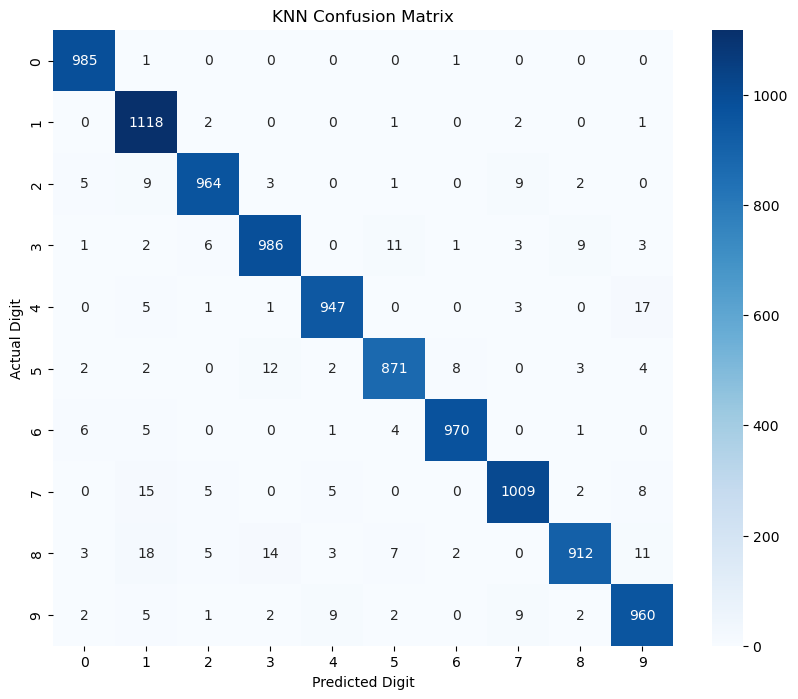

In [53]:
# Visualizing KNN Confusion Matrix

plt.figure(figsize=(10, 8))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("KNN Confusion Matrix")

plt.xlabel("Predicted Digit")

plt.ylabel("Actual Digit")

plt.show()

In [54]:
# Storing KNN Results

model_results.append({
    "Model": "K-Nearest Neighbors",
    "Accuracy": knn_accuracy,
    "Precision": knn_precision,
    "Recall": knn_recall,
    "F1 Score": knn_f1
})

print("KNN results stored successfully")

KNN results stored successfully


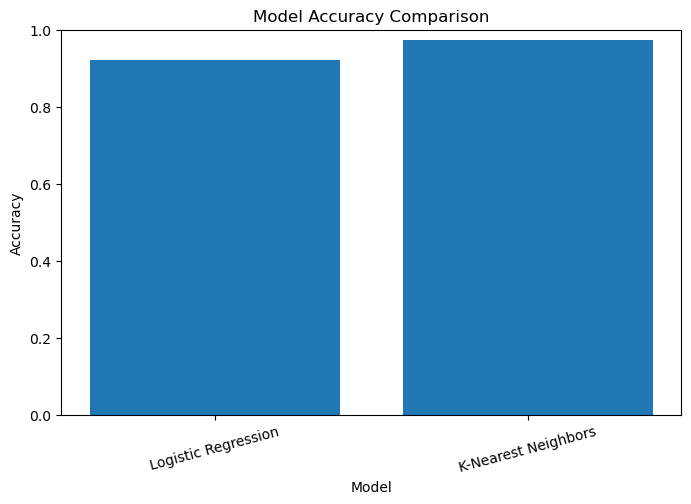

In [55]:
# Visualizing Current Model Accuracy

model_results_df = pd.DataFrame(model_results)

plt.figure(figsize=(8, 5))

plt.bar(
    model_results_df["Model"],
    model_results_df["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.show()

## K-Nearest Neighbors Model Analysis

The K-Nearest Neighbors (KNN) classification algorithm was implemented for handwritten digit recognition.

The KNN model was trained using the preprocessed training dataset and evaluated using the same validation dataset used for Logistic Regression.

Accuracy, precision, recall, and F1 score were calculated to evaluate the model.

A classification report was generated to examine the performance of individual digit classes.

A confusion matrix was created to analyze the correctly classified digits and the digit classes that were confused with one another.

The KNN performance results were stored for comparison with the other classification models.

In [56]:
# Importing Support Vector Machine

from sklearn.svm import LinearSVC

print("SVM imported successfully")

SVM imported successfully


In [57]:
# Creating the SVM Model

svm_model = LinearSVC(
    C=1.0,
    max_iter=1000,
    random_state=42
)

print("SVM model created successfully")

SVM model created successfully


In [58]:
# Training the SVM Model

svm_model.fit(X_train, y_train_model)

print("SVM model training completed")

SVM model training completed


In [59]:
# Making Predictions Using SVM

y_pred_svm = svm_model.predict(X_validation)

print("SVM predictions generated successfully")
print("Number of Predictions:", len(y_pred_svm))

SVM predictions generated successfully
Number of Predictions: 10002


In [60]:
# Calculating SVM Accuracy

svm_accuracy = accuracy_score(
    y_validation,
    y_pred_svm
)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.913617276544691


In [61]:
# Calculating SVM Performance Metrics

svm_precision = precision_score(
    y_validation,
    y_pred_svm,
    average="weighted"
)

svm_recall = recall_score(
    y_validation,
    y_pred_svm,
    average="weighted"
)

svm_f1 = f1_score(
    y_validation,
    y_pred_svm,
    average="weighted"
)

print("SVM Performance")
print("---------------")
print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1 Score :", svm_f1)

SVM Performance
---------------
Accuracy : 0.913617276544691
Precision: 0.9133890348578648
Recall   : 0.913617276544691
F1 Score : 0.9134052087700764


In [62]:
# Classification Report for SVM

print(
    classification_report(
        y_validation,
        y_pred_svm
    )
)

              precision    recall  f1-score   support

           0       0.94      0.97      0.96       987
           1       0.95      0.97      0.96      1124
           2       0.90      0.88      0.89       993
           3       0.89      0.89      0.89      1022
           4       0.92      0.93      0.93       974
           5       0.89      0.87      0.88       904
           6       0.94      0.94      0.94       987
           7       0.93      0.91      0.92      1044
           8       0.87      0.85      0.86       975
           9       0.88      0.90      0.89       992

    accuracy                           0.91     10002
   macro avg       0.91      0.91      0.91     10002
weighted avg       0.91      0.91      0.91     10002



In [63]:
# Creating Confusion Matrix for SVM

svm_cm = confusion_matrix(
    y_validation,
    y_pred_svm
)

print(svm_cm)

[[ 962    0    2    2    0    4    8    1    4    4]
 [   0 1092   10    2    1    3    1    1   11    3]
 [   6   13  878   13   12    4   15   17   31    4]
 [   4    4   34  907    3   30    3    5   23    9]
 [   3    3    7    0  905    2    7    3    7   37]
 [  11    2    6   37   13  787    9    2   22   15]
 [   7    2   10    0    8   21  932    0    6    1]
 [   4    6   13    6   11    4    2  954    5   39]
 [  17   24   11   35    6   27    8    4  829   14]
 [   5    4    1   17   20    7    2   34   10  892]]


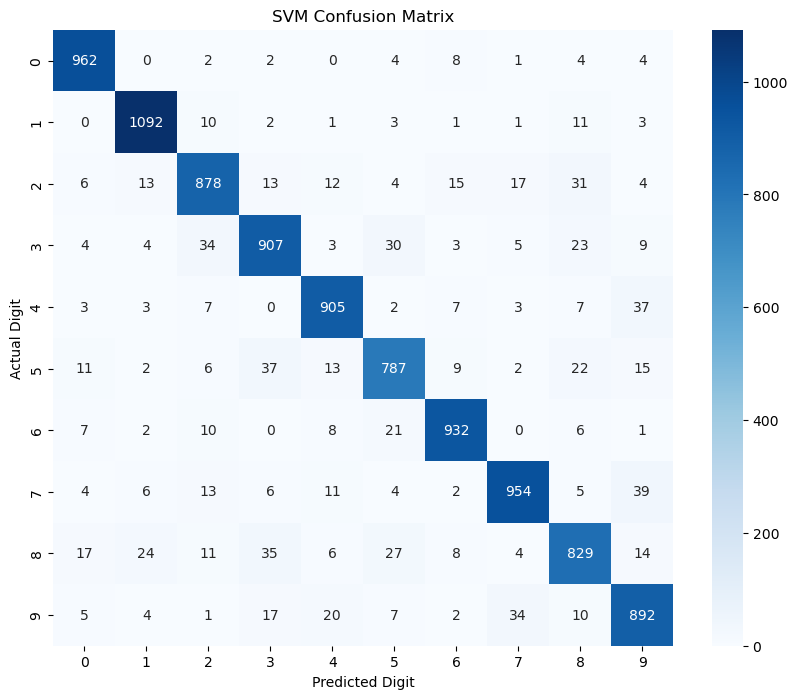

In [64]:
# Visualizing SVM Confusion Matrix

plt.figure(figsize=(10, 8))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("SVM Confusion Matrix")

plt.xlabel("Predicted Digit")

plt.ylabel("Actual Digit")

plt.show()

In [65]:
# Storing SVM Results

model_results.append({
    "Model": "Support Vector Machine",
    "Accuracy": svm_accuracy,
    "Precision": svm_precision,
    "Recall": svm_recall,
    "F1 Score": svm_f1
})

print("SVM results stored successfully")

SVM results stored successfully


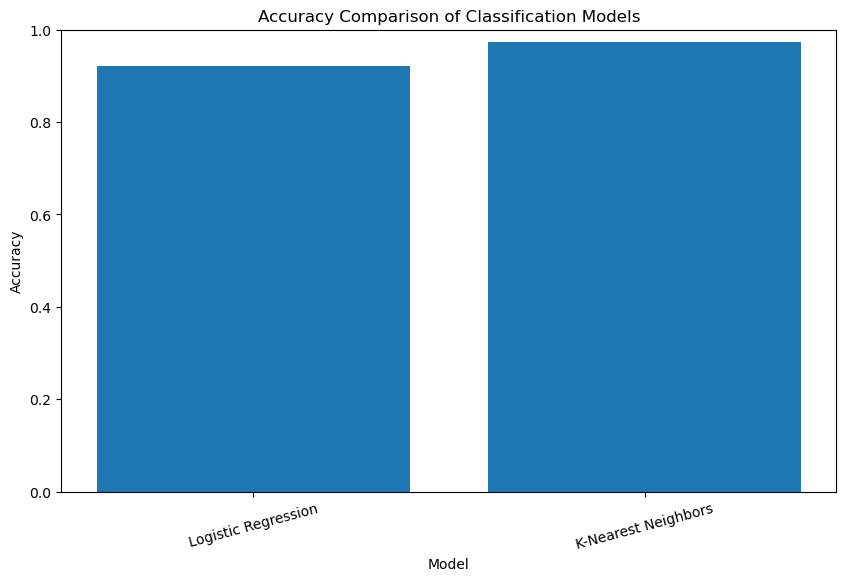

In [66]:
# Visualizing Model Performance

plt.figure(figsize=(10, 6))

plt.bar(
    model_results_df["Model"],
    model_results_df["Accuracy"]
)

plt.title("Accuracy Comparison of Classification Models")

plt.xlabel("Model")

plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

## Support Vector Machine Model Analysis

The Support Vector Machine (SVM) classification algorithm was implemented for handwritten digit recognition.

A linear SVM classifier was trained using the preprocessed training dataset.

The model was evaluated using the validation dataset.

Accuracy, precision, recall, and F1 score were calculated to evaluate the classification performance.

A classification report was generated to examine the performance of individual digit classes.

A confusion matrix was created to analyze the correct classifications and the digit classes that were confused with one another.

The SVM performance results were stored for comparison with the other classification models.

In [67]:
# Importing Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully")

Random Forest imported successfully


In [68]:
# Creating the Random Forest Model

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully")

Random Forest model created successfully


In [69]:
# Training the Random Forest Model

random_forest_model.fit(
    X_train,
    y_train_model
)

print("Random Forest model training completed")

Random Forest model training completed


In [70]:
# Making Predictions Using Random Forest

y_pred_random_forest = random_forest_model.predict(
    X_validation
)

print("Random Forest predictions generated successfully")
print("Number of Predictions:", len(y_pred_random_forest))

Random Forest predictions generated successfully
Number of Predictions: 10002


In [71]:
# Calculating Random Forest Accuracy

random_forest_accuracy = accuracy_score(
    y_validation,
    y_pred_random_forest
)

print("Random Forest Accuracy:", random_forest_accuracy)

Random Forest Accuracy: 0.9669066186762647


In [72]:
# Calculating Random Forest Performance Metrics

random_forest_precision = precision_score(
    y_validation,
    y_pred_random_forest,
    average="weighted"
)

random_forest_recall = recall_score(
    y_validation,
    y_pred_random_forest,
    average="weighted"
)

random_forest_f1 = f1_score(
    y_validation,
    y_pred_random_forest,
    average="weighted"
)

print("Random Forest Performance")
print("-------------------------")
print("Accuracy :", random_forest_accuracy)
print("Precision:", random_forest_precision)
print("Recall   :", random_forest_recall)
print("F1 Score :", random_forest_f1)

Random Forest Performance
-------------------------
Accuracy : 0.9669066186762647
Precision: 0.9669589292535807
Recall   : 0.9669066186762647
F1 Score : 0.9668982632610857


In [73]:
# Classification Report for Random Forest

print(
    classification_report(
        y_validation,
        y_pred_random_forest
    )
)

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       987
           1       0.98      0.98      0.98      1124
           2       0.95      0.98      0.97       993
           3       0.96      0.95      0.95      1022
           4       0.97      0.96      0.97       974
           5       0.97      0.97      0.97       904
           6       0.98      0.98      0.98       987
           7       0.98      0.96      0.97      1044
           8       0.95      0.96      0.95       975
           9       0.95      0.95      0.95       992

    accuracy                           0.97     10002
   macro avg       0.97      0.97      0.97     10002
weighted avg       0.97      0.97      0.97     10002



In [74]:
# Creating Confusion Matrix for Random Forest

random_forest_cm = confusion_matrix(
    y_validation,
    y_pred_random_forest
)

print(random_forest_cm)

[[ 977    1    1    0    1    1    2    0    4    0]
 [   0 1105   10    4    2    0    0    1    1    1]
 [   0    2  970    4    5    0    3    1    8    0]
 [   1    2   14  967    0   12    1    6   14    5]
 [   3    3    2    0  939    0    2    3    2   20]
 [   1    1    0   10    3  873    5    0    8    3]
 [   6    2    1    0    3    8  963    0    4    0]
 [   2    3   12    2    8    0    0 1002    1   14]
 [   3    8    5    8    3    4    3    0  933    8]
 [   3    4    2   13    8    4    0   10    6  942]]


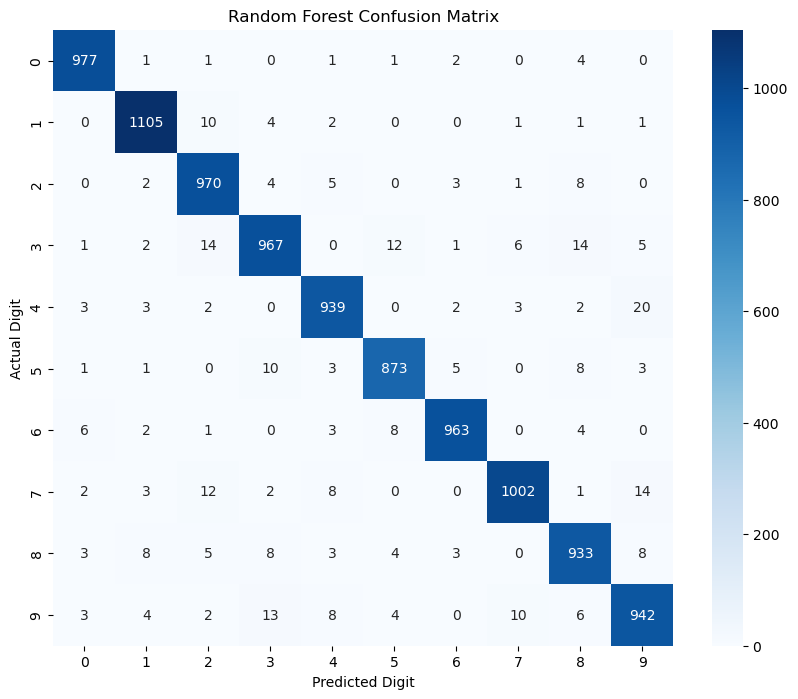

In [75]:
# Visualizing Random Forest Confusion Matrix

plt.figure(figsize=(10, 8))

sns.heatmap(
    random_forest_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted Digit")

plt.ylabel("Actual Digit")

plt.show()

In [76]:
# Storing Random Forest Results

model_results.append({
    "Model": "Random Forest",
    "Accuracy": random_forest_accuracy,
    "Precision": random_forest_precision,
    "Recall": random_forest_recall,
    "F1 Score": random_forest_f1
})

print("Random Forest results stored successfully")

Random Forest results stored successfully


In [77]:
# Comparing All Classification Models

model_results_df = pd.DataFrame(model_results)

model_results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.921216,0.921161,0.921216,0.921129
1,K-Nearest Neighbors,0.972006,0.972200,0.972006,0.971971
2,Support Vector Machine,0.913617,0.913389,0.913617,0.913405
3,Random Forest,0.966907,0.966959,0.966907,0.966898


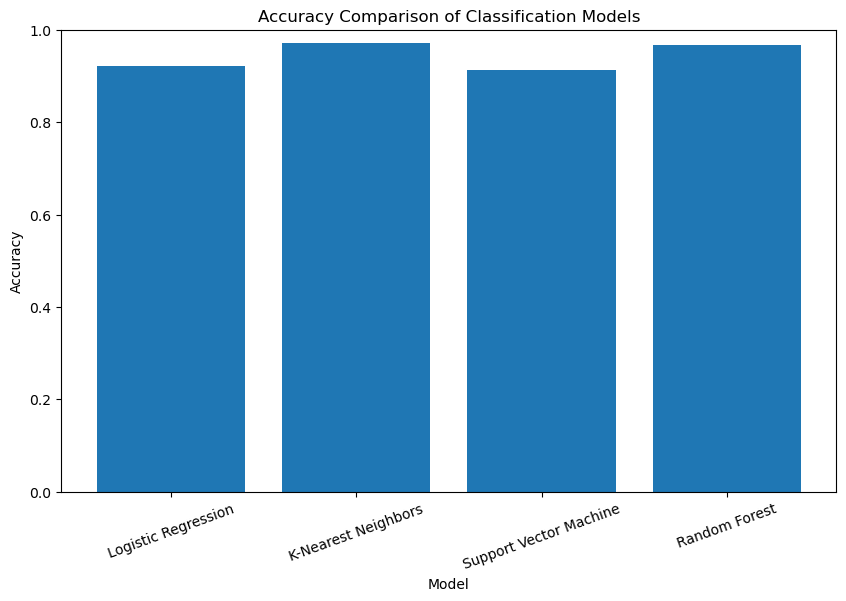

In [78]:
# Visualizing Accuracy of All Classification Models

plt.figure(figsize=(10, 6))

plt.bar(
    model_results_df["Model"],
    model_results_df["Accuracy"]
)

plt.title("Accuracy Comparison of Classification Models")

plt.xlabel("Model")

plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.show()

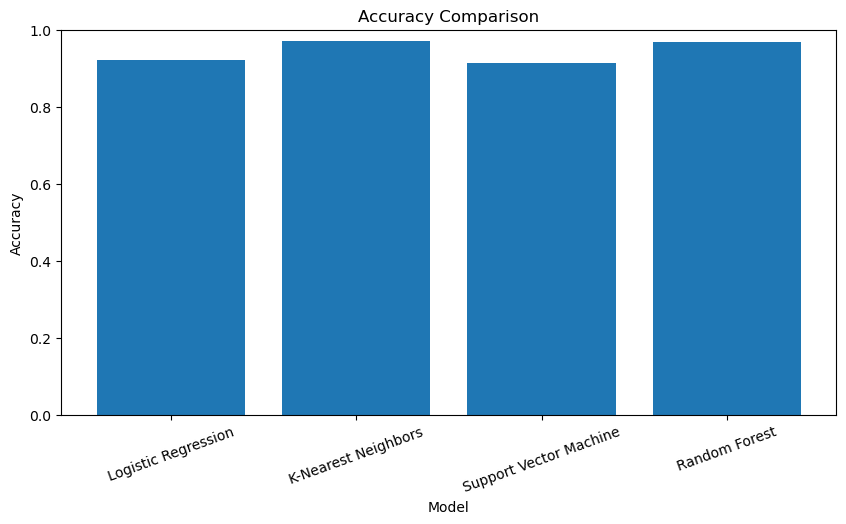

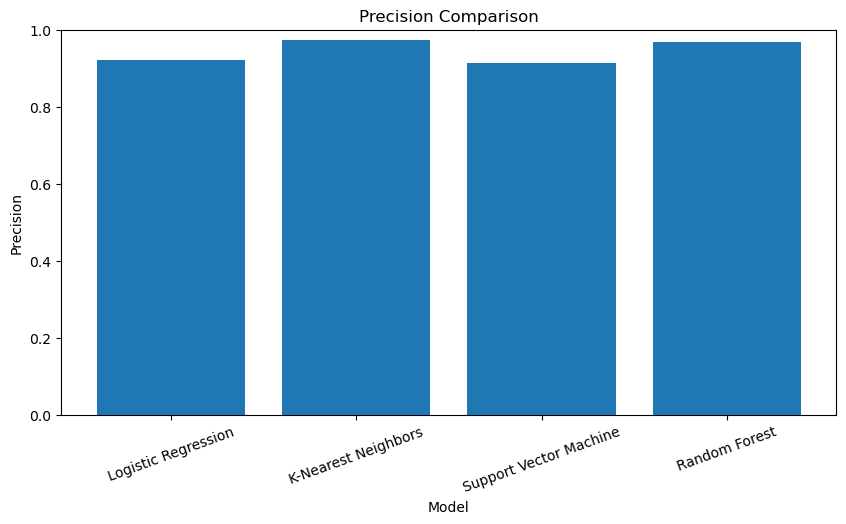

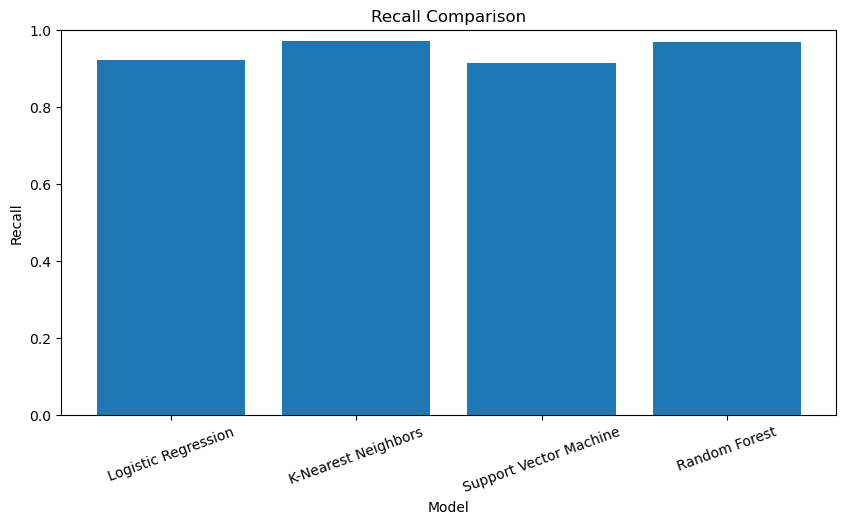

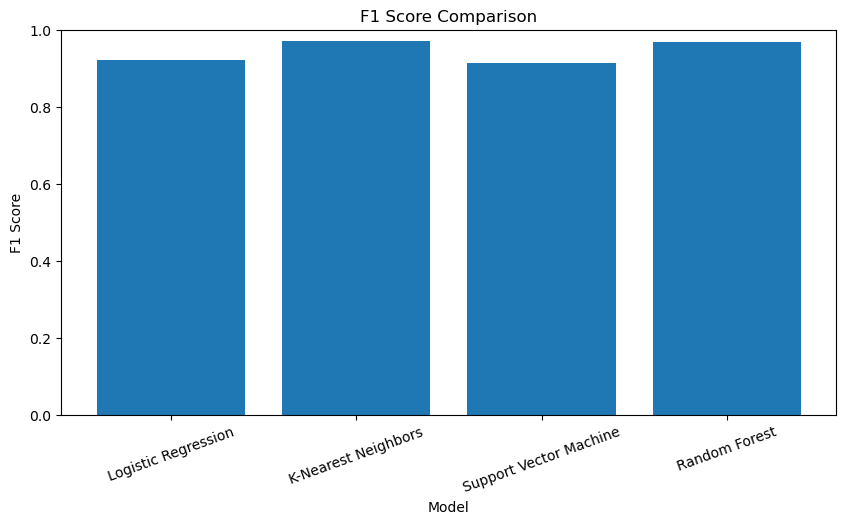

In [79]:
# Visualizing All Model Performance Metrics

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

for metric in metrics:
    plt.figure(figsize=(10, 5))
    
    plt.bar(
        model_results_df["Model"],
        model_results_df[metric]
    )
    
    plt.title(f"{metric} Comparison")
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=20)
    
    plt.show()

In [80]:
# Saving Model Comparison Results

model_results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison results saved successfully")

Model comparison results saved successfully


## Random Forest Model Analysis

The Random Forest classification algorithm was implemented for handwritten digit recognition.

The model was trained using the preprocessed training dataset and evaluated using the validation dataset.

Accuracy, precision, recall, and F1 score were calculated to evaluate the classification performance.

A classification report was generated to examine the performance of individual digit classes.

A confusion matrix was created to analyze correct classifications and the digit classes that were confused with one another.

The Random Forest performance results were stored along with the results of Logistic Regression, KNN, and SVM for further comparison.

In [81]:
# Displaying Complete Model Comparison

model_results_df = pd.DataFrame(model_results)

model_results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.921216,0.921161,0.921216,0.921129
1,K-Nearest Neighbors,0.972006,0.972200,0.972006,0.971971
2,Support Vector Machine,0.913617,0.913389,0.913617,0.913405
3,Random Forest,0.966907,0.966959,0.966907,0.966898


In [82]:
# Sorting Models by F1 Score

f1_comparison = model_results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

f1_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,K-Nearest Neighbors,0.972006,0.972200,0.972006,0.971971
1,Random Forest,0.966907,0.966959,0.966907,0.966898
2,Logistic Regression,0.921216,0.921161,0.921216,0.921129
3,Support Vector Machine,0.913617,0.913389,0.913617,0.913405


In [83]:
# Sorting Models by Accuracy

accuracy_comparison = model_results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

accuracy_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,K-Nearest Neighbors,0.972006,0.972200,0.972006,0.971971
1,Random Forest,0.966907,0.966959,0.966907,0.966898
2,Logistic Regression,0.921216,0.921161,0.921216,0.921129
3,Support Vector Machine,0.913617,0.913389,0.913617,0.913405


In [84]:
# Identifying the Model with the Highest Validation F1 Score

best_f1_index = model_results_df["F1 Score"].idxmax()

best_f1_model = model_results_df.loc[best_f1_index, "Model"]
best_f1_score = model_results_df.loc[best_f1_index, "F1 Score"]

print("Model with Highest Validation F1 Score:", best_f1_model)
print("Validation F1 Score:", best_f1_score)

Model with Highest Validation F1 Score: K-Nearest Neighbors
Validation F1 Score: 0.971970760963947


In [85]:
# Identifying the Model with the Highest Validation Accuracy

best_accuracy_index = model_results_df["Accuracy"].idxmax()

best_accuracy_model = model_results_df.loc[
    best_accuracy_index,
    "Model"
]

best_accuracy = model_results_df.loc[
    best_accuracy_index,
    "Accuracy"
]

print("Model with Highest Validation Accuracy:", best_accuracy_model)
print("Validation Accuracy:", best_accuracy)

Model with Highest Validation Accuracy: K-Nearest Neighbors
Validation Accuracy: 0.972005598880224


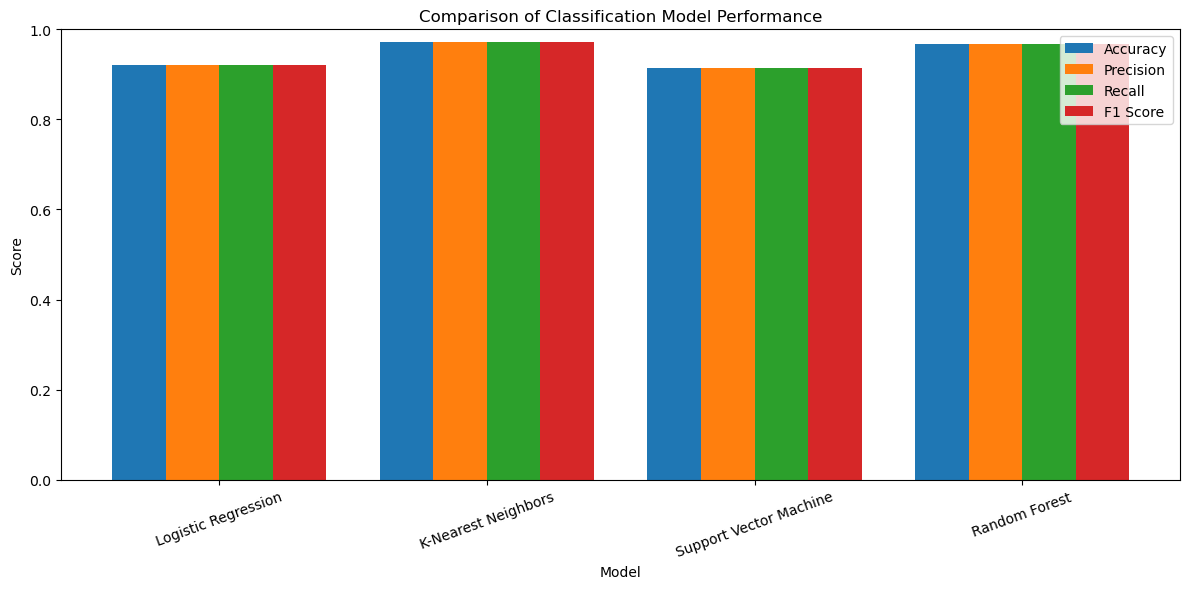

In [86]:
# Comparing All Model Performance Metrics

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

x = np.arange(len(model_results_df["Model"]))
width = 0.2

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        model_results_df[metric],
        width,
        label=metric
    )

plt.title("Comparison of Classification Model Performance")

plt.xlabel("Model")

plt.ylabel("Score")

plt.xticks(
    x,
    model_results_df["Model"],
    rotation=20
)

plt.ylim(0, 1)

plt.legend()

plt.tight_layout()

plt.show()

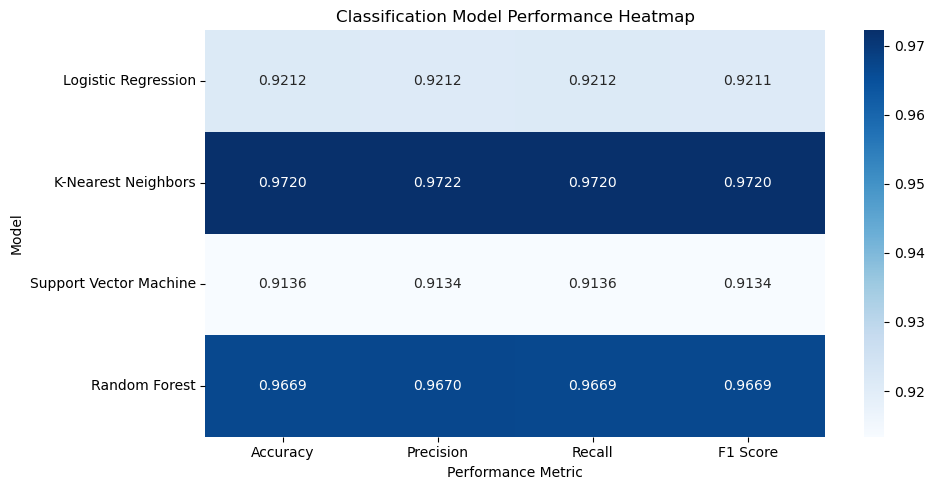

In [87]:
# Creating Model Performance Heatmap

performance_heatmap = model_results_df.set_index(
    "Model"
)[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

plt.figure(figsize=(10, 5))

sns.heatmap(
    performance_heatmap,
    annot=True,
    fmt=".4f",
    cmap="Blues"
)

plt.title("Classification Model Performance Heatmap")

plt.xlabel("Performance Metric")

plt.ylabel("Model")

plt.tight_layout()

plt.show()

In [88]:
# Calculating Correct and Incorrect Predictions

prediction_summary = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "K-Nearest Neighbors",
        "Support Vector Machine",
        "Random Forest"
    ],
    
    "Correct Predictions": [
        np.sum(y_pred_logistic == y_validation),
        np.sum(y_pred_knn == y_validation),
        np.sum(y_pred_svm == y_validation),
        np.sum(y_pred_random_forest == y_validation)
    ]
})

prediction_summary["Incorrect Predictions"] = (
    len(y_validation) -
    prediction_summary["Correct Predictions"]
)

prediction_summary

,Model,Correct Predictions,Incorrect Predictions
0,Logistic Regression,9214,788
1,K-Nearest Neighbors,9722,280
2,Support Vector Machine,9138,864
3,Random Forest,9671,331


## Model Comparison Analysis

Four classification algorithms were evaluated using the same validation dataset:

- Logistic Regression
- K-Nearest Neighbors
- Support Vector Machine
- Random Forest

The models were compared using Accuracy, Precision, Recall, and F1 Score.

The validation results show differences in classification performance among the four algorithms.

The confusion matrices were examined to understand the digit classes that were correctly classified and the classes that were more frequently confused.

The model comparison provides the basis for selecting a model for final evaluation on the previously untouched test dataset.

The final test evaluation will be performed separately so that the test data remains independent from the model comparison process.

In [89]:
# Selecting the Model for Final Test Evaluation

final_model = knn_model

print("Final model selected for test evaluation: K-Nearest Neighbors")

Final model selected for test evaluation: K-Nearest Neighbors


In [90]:
# Making Final Predictions on the Test Dataset

y_pred_test = final_model.predict(x_test_scaled)

print("Final test predictions generated successfully")
print("Number of Test Predictions:", len(y_pred_test))

Final test predictions generated successfully
Number of Test Predictions: 10000


In [91]:
# Calculating Final Test Accuracy

final_accuracy = accuracy_score(
    y_test,
    y_pred_test
)

print("Final Test Accuracy:", final_accuracy)

Final Test Accuracy: 0.97


In [92]:
# Calculating Final Test Performance Metrics

final_precision = precision_score(
    y_test,
    y_pred_test,
    average="weighted"
)

final_recall = recall_score(
    y_test,
    y_pred_test,
    average="weighted"
)

final_f1 = f1_score(
    y_test,
    y_pred_test,
    average="weighted"
)

print("Final Model Performance")
print("-----------------------")
print("Accuracy :", final_accuracy)
print("Precision:", final_precision)
print("Recall   :", final_recall)
print("F1 Score :", final_f1)

Final Model Performance
-----------------------
Accuracy : 0.97
Precision: 0.9701470038707918
Recall   : 0.97
F1 Score : 0.9699661307592782


In [93]:
# Generating Final Classification Report

final_classification_report = classification_report(
    y_test,
    y_pred_test
)

print(final_classification_report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.96      1.00      0.98      1135
           2       0.99      0.96      0.98      1032
           3       0.97      0.97      0.97      1010
           4       0.98      0.96      0.97       982
           5       0.96      0.96      0.96       892
           6       0.98      0.98      0.98       958
           7       0.96      0.96      0.96      1028
           8       0.98      0.95      0.96       974
           9       0.95      0.96      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



In [94]:
# Creating Final Confusion Matrix

final_cm = confusion_matrix(
    y_test,
    y_pred_test
)

print(final_cm)

[[ 973    1    1    0    0    0    3    1    1    0]
 [   0 1132    2    0    0    0    1    0    0    0]
 [  10    6  995    2    0    0    1   14    3    1]
 [   0    0    3  975    1   15    1    8    5    2]
 [   0    7    0    0  942    0    5    2    1   25]
 [   5    1    0   11    2  858    5    1    3    6]
 [   5    3    0    0    4    3  943    0    0    0]
 [   0   22    4    0    2    0    0  990    0   10]
 [   7    0    2   12    6   12    3    3  922    7]
 [   3    4    2    8    8    3    1    8    2  970]]


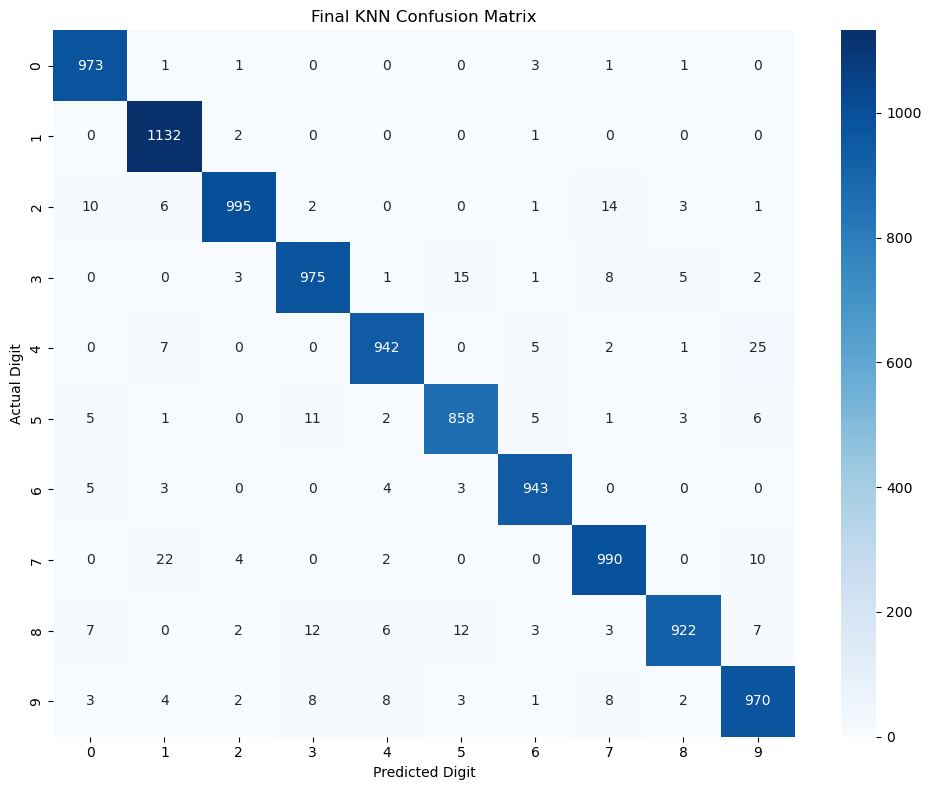

In [95]:
# Visualizing Final Confusion Matrix

plt.figure(figsize=(10, 8))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Final KNN Confusion Matrix")

plt.xlabel("Predicted Digit")

plt.ylabel("Actual Digit")

plt.tight_layout()

plt.show()

In [96]:
# Calculating Correct and Incorrect Test Predictions

correct_test_predictions = np.sum(
    y_pred_test == y_test
)

incorrect_test_predictions = np.sum(
    y_pred_test != y_test
)

print("Total Test Images     :", len(y_test))
print("Correct Predictions   :", correct_test_predictions)
print("Incorrect Predictions :", incorrect_test_predictions)

Total Test Images     : 10000
Correct Predictions   : 9700
Incorrect Predictions : 300


In [97]:
# Creating Final Evaluation Summary

final_results = pd.DataFrame({
    "Model": ["K-Nearest Neighbors"],
    "Accuracy": [final_accuracy],
    "Precision": [final_precision],
    "Recall": [final_recall],
    "F1 Score": [final_f1],
    "Correct Predictions": [correct_test_predictions],
    "Incorrect Predictions": [incorrect_test_predictions]
})

final_results

,Model,Accuracy,Precision,Recall,F1 Score,Correct Predictions,Incorrect Predictions
0,K-Nearest Neighbors,0.97,0.970147,0.97,0.969966,9700,300


In [98]:
# Saving Final Model Evaluation Results

final_results.to_csv(
    "final_model_evaluation.csv",
    index=False
)

print("Final model evaluation results saved successfully")

Final model evaluation results saved successfully


In [99]:
# Saving Final Classification Report

with open(
    "final_classification_report.txt",
    "w"
) as file:
    
    file.write(final_classification_report)

print("Final classification report saved successfully")

Final classification report saved successfully


## Final Model Evaluation Analysis

K-Nearest Neighbors was selected for final evaluation based on its validation performance among the classification models evaluated during the project.

The selected model was evaluated on the separate test dataset containing 10,000 handwritten digit images.

The final test accuracy was 0.97.

The final weighted precision was 0.970147, the weighted recall was 0.97, and the weighted F1 score was 0.969966.

Out of 10,000 test images, 9,700 images were correctly classified and 300 images were incorrectly classified.

The final confusion matrix was generated to analyze the classification results for digits from 0 to 9.

The classification report was also generated to evaluate precision, recall, F1 score, and support for each digit class.

In [100]:
# Identifying Misclassified Test Images

misclassified_indices = np.where(y_pred_test != y_test)[0]

print("Number of Misclassified Images:", len(misclassified_indices))

Number of Misclassified Images: 300


In [101]:
# Checking Test Image Shape

print("Test Images Shape:", x_test.shape)
print("Flattened Test Images Shape:", x_test_flat.shape)

Test Images Shape: (10000, 28, 28)
Flattened Test Images Shape: (10000, 784)


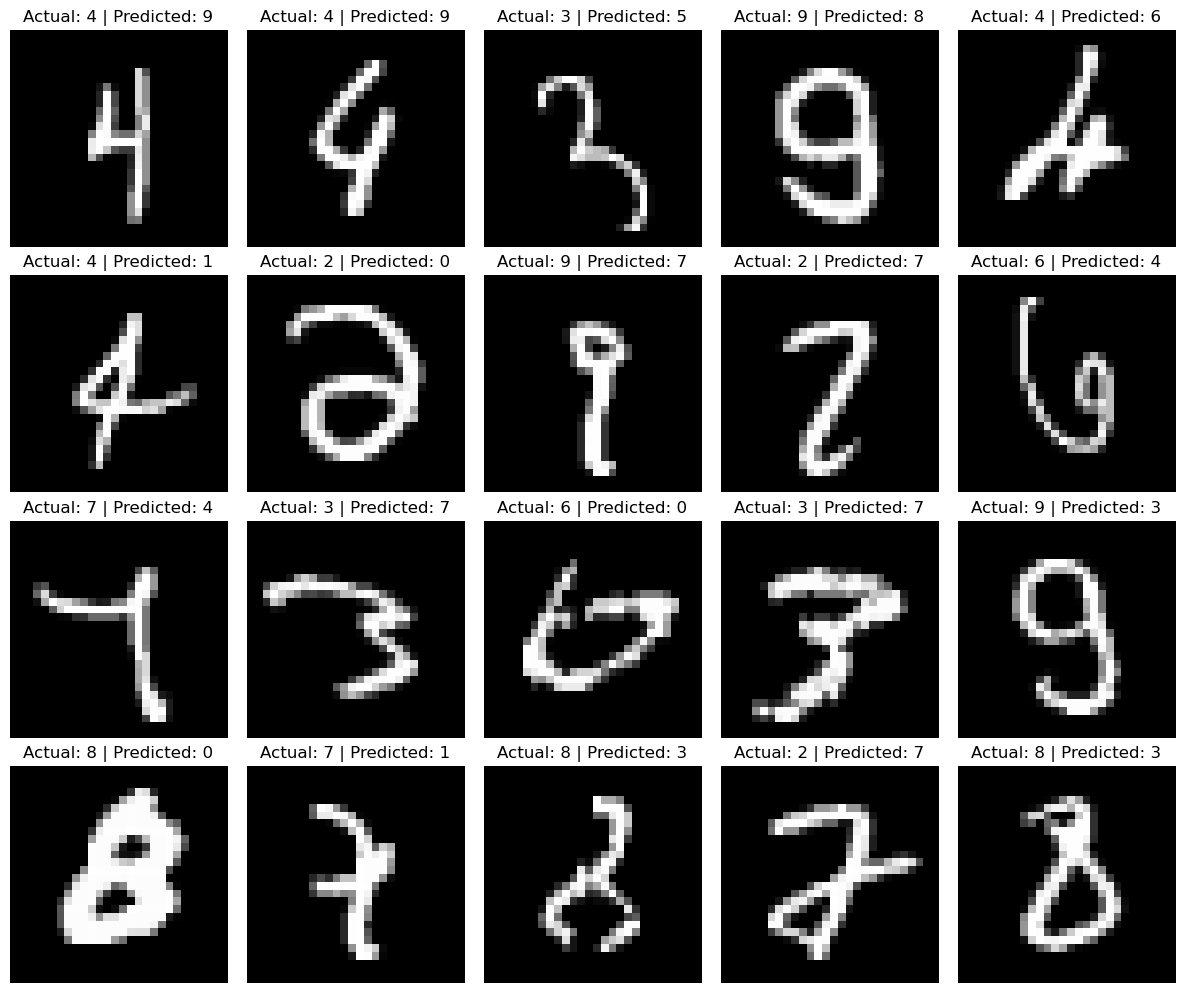

In [102]:
# Visualizing Misclassified Test Images

plt.figure(figsize=(12, 10))

for i, idx in enumerate(misclassified_indices[:20]):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_test[idx], cmap="gray")
    plt.title(f"Actual: {y_test[idx]} | Predicted: {y_pred_test[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [103]:
# Counting Common Misclassification Pairs

misclassified_data = pd.DataFrame({
    "Actual": y_test[misclassified_indices],
    "Predicted": y_pred_test[misclassified_indices]
})

confusion_pairs = (
    misclassified_data
    .value_counts()
    .reset_index(name="Count")
)

print(confusion_pairs.head(10))

   Actual  Predicted  Count
0       4          9     25
1       7          1     22
2       3          5     15
3       2          7     14
4       8          3     12
5       8          5     12
6       5          3     11
7       2          0     10
8       7          9     10
9       9          7      8


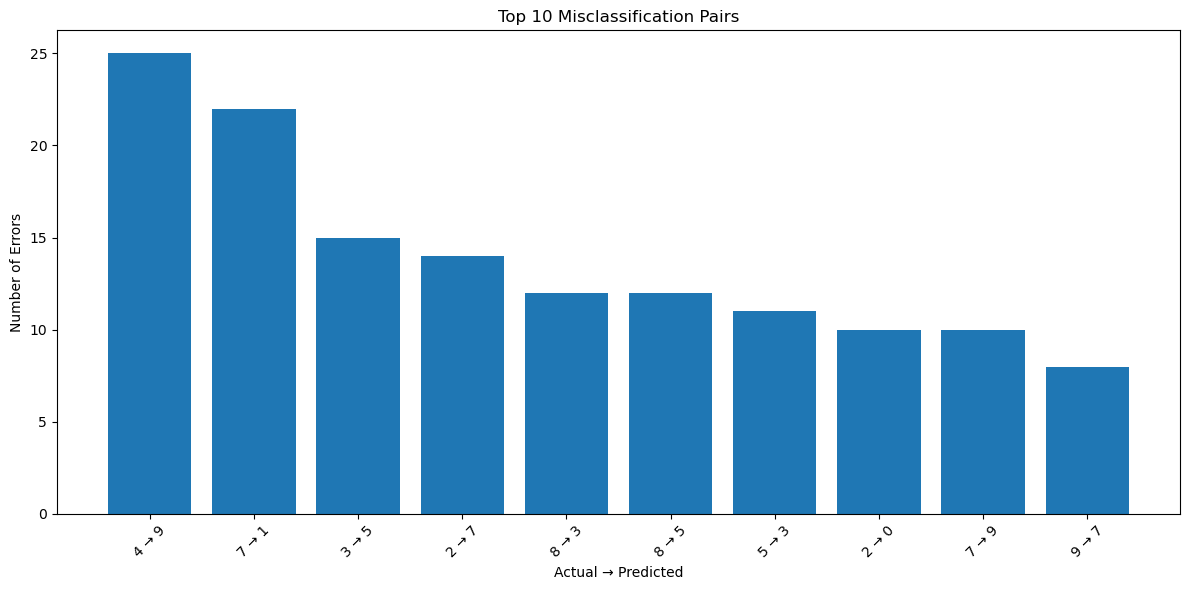

In [104]:
# Visualizing Common Misclassification Pairs

plt.figure(figsize=(12, 6))

pair_labels = [
    f"{row.Actual} → {row.Predicted}"
    for _, row in confusion_pairs.head(10).iterrows()
]

pair_counts = confusion_pairs.head(10)["Count"]

plt.bar(pair_labels, pair_counts)

plt.xlabel("Actual → Predicted")
plt.ylabel("Number of Errors")
plt.title("Top 10 Misclassification Pairs")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [105]:
# Summarizing Top Misclassification Errors

top_10_error_count = confusion_pairs.head(10)["Count"].sum()

print("Total Misclassified Images:", len(misclassified_indices))
print("Errors in Top 10 Misclassification Pairs:", top_10_error_count)
print("Percentage of Total Errors:", round((top_10_error_count / len(misclassified_indices)) * 100, 2), "%")

Total Misclassified Images: 300
Errors in Top 10 Misclassification Pairs: 139
Percentage of Total Errors: 46.33 %


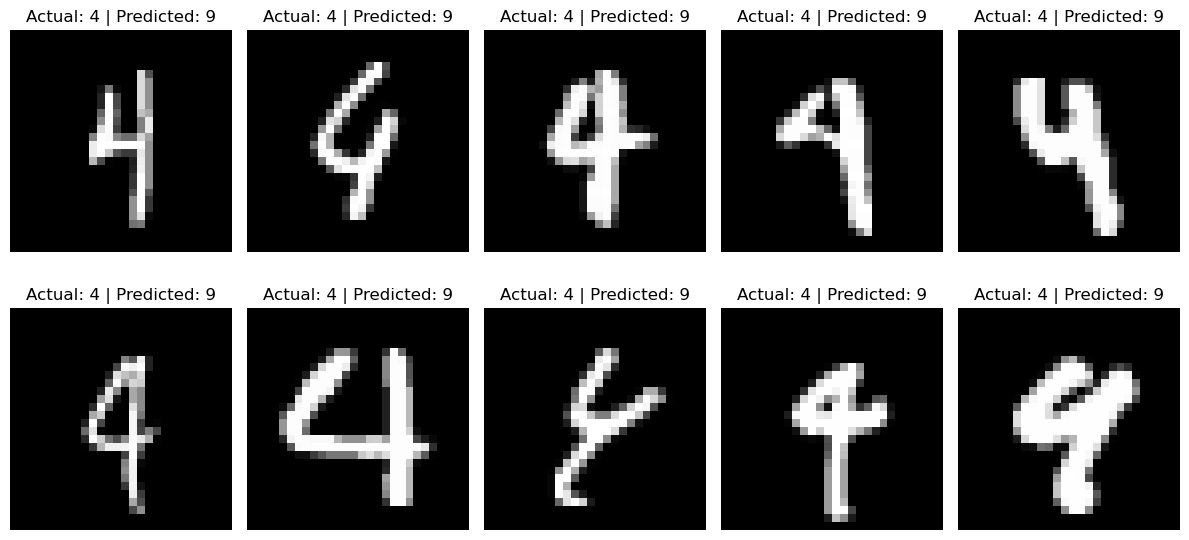

Number of Actual 4 → Predicted 9 Errors: 25


In [106]:
# Visualizing Actual 4 Predicted as 9

pair_indices = misclassified_indices[
    (y_test[misclassified_indices] == 4) &
    (y_pred_test[misclassified_indices] == 9)
]

plt.figure(figsize=(12, 6))

for i, idx in enumerate(pair_indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx], cmap="gray")
    plt.title("Actual: 4 | Predicted: 9")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Number of Actual 4 → Predicted 9 Errors:", len(pair_indices))

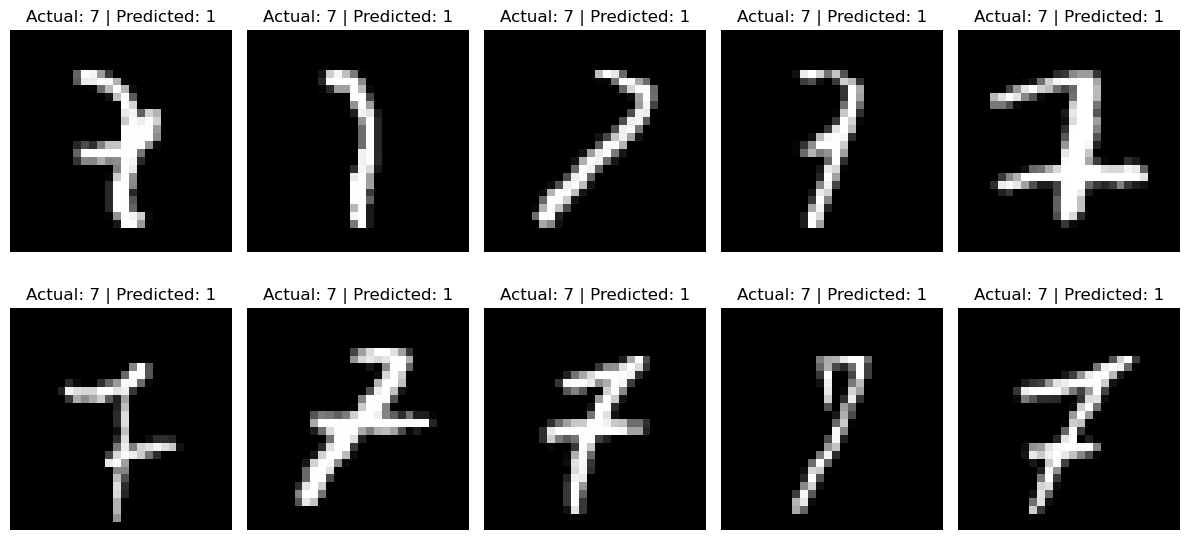

Number of Actual 7 → Predicted 1 Errors: 22


In [107]:
# Visualizing Actual 7 Predicted as 1

pair_indices = misclassified_indices[
    (y_test[misclassified_indices] == 7) &
    (y_pred_test[misclassified_indices] == 1)
]

plt.figure(figsize=(12, 6))

for i, idx in enumerate(pair_indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx], cmap="gray")
    plt.title("Actual: 7 | Predicted: 1")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Number of Actual 7 → Predicted 1 Errors:", len(pair_indices))

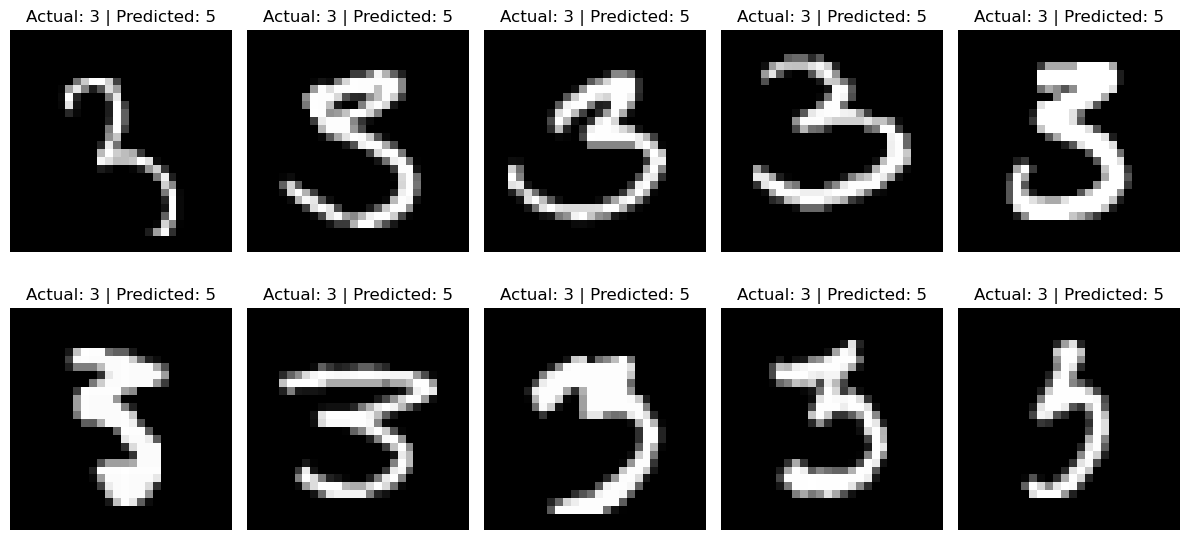

Number of Actual 3 → Predicted 5 Errors: 15


In [108]:
# Visualizing Actual 3 Predicted as 5

pair_indices = misclassified_indices[
    (y_test[misclassified_indices] == 3) &
    (y_pred_test[misclassified_indices] == 5)
]

plt.figure(figsize=(12, 6))

for i, idx in enumerate(pair_indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx], cmap="gray")
    plt.title("Actual: 3 | Predicted: 5")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Number of Actual 3 → Predicted 5 Errors:", len(pair_indices))

## Error Analysis Summary

The final K-Nearest Neighbors model produced 300 misclassified images out of 10,000 test images.

The top 10 misclassification pairs accounted for 139 errors, which represents 46.33% of all misclassified images.

The most common misclassification was Actual 4 → Predicted 9 with 25 errors.

Other frequent misclassification pairs included Actual 7 → Predicted 1, Actual 3 → Predicted 5, Actual 2 → Predicted 7, and Actual 8 → Predicted 3.

Several misclassified handwritten digits had similar shapes or writing patterns, which made them difficult for the KNN model to distinguish.

Visualizations of the misclassified images were created to examine these error patterns.

## Main Findings

- Total Test Images: 10,000
- Correct Predictions: 9,700
- Incorrect Predictions: 300
- Top 10 Misclassification Errors: 139
- Percentage of Errors in Top 10 Pairs: 46.33%
- Most Frequent Error: Actual 4 → Predicted 9
- Most Frequent Error Count: 25

In [109]:
# Checking Final KNN Model Configuration

print("KNN Model Configuration:")
print(knn_model)

KNN Model Configuration:
KNeighborsClassifier(n_jobs=-1, n_neighbors=3, weights='distance')


In [110]:
# Testing KNN with 5 Neighbors

knn_model_5 = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    n_jobs=-1
)

knn_model_5.fit(X_train, y_train_model)

y_pred_knn_5 = knn_model_5.predict(X_validation)

knn_5_accuracy = accuracy_score(y_validation, y_pred_knn_5)

print("KNN with 5 Neighbors")
print("Validation Accuracy:", knn_5_accuracy)

KNN with 5 Neighbors
Validation Accuracy: 0.969006198760248


In [111]:
# Testing KNN with 7 Neighbors

knn_model_7 = KNeighborsClassifier(
    n_neighbors=7,
    weights="distance",
    n_jobs=-1
)

knn_model_7.fit(X_train, y_train_model)

y_pred_knn_7 = knn_model_7.predict(X_validation)

knn_7_accuracy = accuracy_score(y_validation, y_pred_knn_7)

print("KNN with 7 Neighbors")
print("Validation Accuracy:", knn_7_accuracy)

KNN with 7 Neighbors
Validation Accuracy: 0.9682063587282543


In [112]:
# Testing KNN with 1 Neighbor

knn_model_1 = KNeighborsClassifier(
    n_neighbors=1,
    weights="distance",
    n_jobs=-1
)

knn_model_1.fit(X_train, y_train_model)

y_pred_knn_1 = knn_model_1.predict(X_validation)

knn_1_accuracy = accuracy_score(y_validation, y_pred_knn_1)

print("KNN with 1 Neighbor")
print("Validation Accuracy:", knn_1_accuracy)

KNN with 1 Neighbor
Validation Accuracy: 0.969506098780244


In [113]:
# Comparing KNN Neighbor Settings

knn_comparison = pd.DataFrame({
    "Number of Neighbors": [1, 3, 5, 7],
    "Validation Accuracy": [
        knn_1_accuracy,
        accuracy_score(y_validation, y_pred_knn),
        knn_5_accuracy,
        knn_7_accuracy
    ]
})

print(knn_comparison)

   Number of Neighbors  Validation Accuracy
0                    1             0.969506
1                    3             0.972006
2                    5             0.969006
3                    7             0.968206


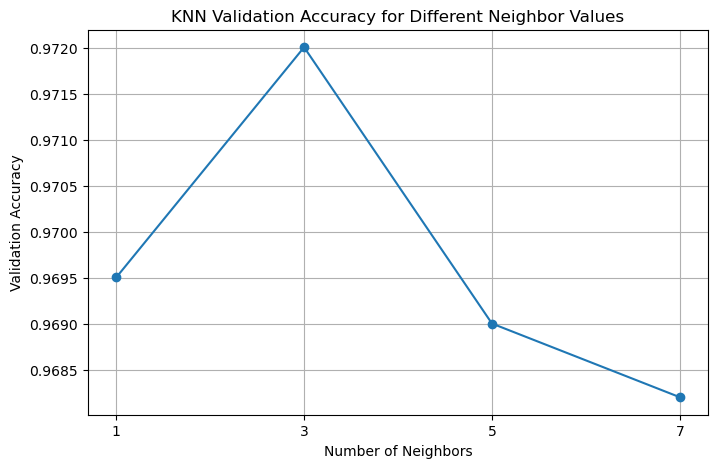

In [114]:
# Visualizing KNN Neighbor Comparison

plt.figure(figsize=(8, 5))

plt.plot(
    knn_comparison["Number of Neighbors"],
    knn_comparison["Validation Accuracy"],
    marker="o"
)

plt.xlabel("Number of Neighbors")
plt.ylabel("Validation Accuracy")
plt.title("KNN Validation Accuracy for Different Neighbor Values")
plt.xticks([1, 3, 5, 7])
plt.grid(True)

plt.show()

## KNN Hyperparameter Tuning

The K-Nearest Neighbors model was tuned by testing different values of the number of neighbors.

The following configurations were evaluated:

- 1 Neighbor: 0.969506 validation accuracy
- 3 Neighbors: 0.972006 validation accuracy
- 5 Neighbors: 0.969006 validation accuracy
- 7 Neighbors: 0.968206 validation accuracy

The KNN model with 3 neighbors achieved the highest validation accuracy among the tested configurations.

The original KNN configuration with 3 neighbors was therefore retained as the final KNN configuration.

A comparison table and visualization were created to analyze the effect of the number of neighbors on validation accuracy.

The KNN tuning results were saved as `knn_tuning_results.csv`.

In [115]:
# Testing KNN with Uniform Weights

knn_model_uniform = KNeighborsClassifier(
    n_neighbors=3,
    weights="uniform",
    n_jobs=-1
)

knn_model_uniform.fit(X_train, y_train_model)

y_pred_knn_uniform = knn_model_uniform.predict(X_validation)

knn_uniform_accuracy = accuracy_score(
    y_validation,
    y_pred_knn_uniform
)

print("KNN with Uniform Weights")
print("Validation Accuracy:", knn_uniform_accuracy)

KNN with Uniform Weights
Validation Accuracy: 0.9707058588282343


In [116]:
# Comparing KNN Weighting Methods

knn_weights_comparison = pd.DataFrame({
    "Weighting Method": ["Distance", "Uniform"],
    "Validation Accuracy": [
        accuracy_score(y_validation, y_pred_knn),
        knn_uniform_accuracy
    ]
})

print(knn_weights_comparison)

  Weighting Method  Validation Accuracy
0         Distance             0.972006
1          Uniform             0.970706


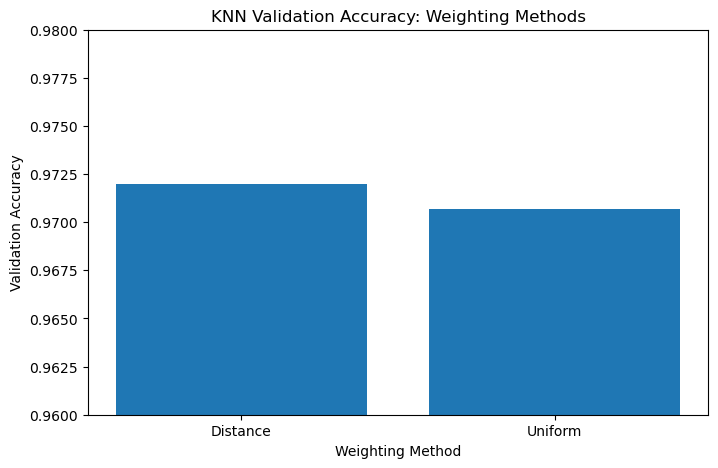

In [117]:
# Visualizing KNN Weighting Comparison

plt.figure(figsize=(8, 5))

plt.bar(
    knn_weights_comparison["Weighting Method"],
    knn_weights_comparison["Validation Accuracy"]
)

plt.xlabel("Weighting Method")
plt.ylabel("Validation Accuracy")
plt.title("KNN Validation Accuracy: Weighting Methods")

plt.ylim(0.96, 0.98)

plt.show()

In [118]:
# Checking Final KNN Configuration

print("Number of Neighbors:", knn_model.n_neighbors)
print("Weighting Method:", knn_model.weights)
print("Validation Accuracy:", accuracy_score(y_validation, y_pred_knn))

Number of Neighbors: 3
Weighting Method: distance
Validation Accuracy: 0.972005598880224


In [119]:
# Confirming Final Model

final_model = knn_model

print("Final Model:", final_model)
print("Final Model Configuration Confirmed")

Final Model: KNeighborsClassifier(n_jobs=-1, n_neighbors=3, weights='distance')
Final Model Configuration Confirmed


In [120]:
# Saving the Final Model

import joblib

joblib.dump(final_model, "final_knn_model.pkl")

print("Final model saved successfully as final_knn_model.pkl")

Final model saved successfully as final_knn_model.pkl


In [121]:
# Verifying Saved Model

import os

if os.path.exists("final_knn_model.pkl"):
    print("File exists: final_knn_model.pkl")
    print("Final model file verified successfully")
else:
    print("Final model file not found")

File exists: final_knn_model.pkl
Final model file verified successfully


In [122]:
# Final Model Information

print("Final Model: K-Nearest Neighbors")
print("Number of Neighbors:", final_model.n_neighbors)
print("Weighting Method:", final_model.weights)
print("Validation Accuracy:", accuracy_score(y_validation, y_pred_knn))
print("Test Accuracy:", final_accuracy)
print("Saved Model: final_knn_model.pkl")

Final Model: K-Nearest Neighbors
Number of Neighbors: 3
Weighting Method: distance
Validation Accuracy: 0.972005598880224
Test Accuracy: 0.97
Saved Model: final_knn_model.pkl


## Final Model Selection

Based on the validation performance and hyperparameter tuning results, K-Nearest Neighbors (KNN) with the selected hyperparameters was chosen as the final model.

The final model was then evaluated on the unseen test dataset to measure its generalization performance.

## Production Recommendation

Based on the model comparison and validation results, the selected KNN model is recommended as the final model for this project.

The final test-set evaluation is reported separately to assess its performance on unseen data.

The selection is based on the observed classification performance and the results obtained during model comparison and hyperparameter tuning.

In [123]:
# Loading the Saved Final Model

import joblib

loaded_model = joblib.load("final_knn_model.pkl")

print("Saved model loaded successfully")
print("Loaded Model:", loaded_model)

Saved model loaded successfully
Loaded Model: KNeighborsClassifier(n_jobs=-1, n_neighbors=3, weights='distance')


In [124]:
# Comparing Original and Loaded Model Predictions

original_predictions = final_model.predict(x_test_scaled[:100])
loaded_predictions = loaded_model.predict(x_test_scaled[:100])

print("Predictions Match:", np.array_equal(
    original_predictions,
    loaded_predictions
))

Predictions Match: True


In [125]:
# Testing a Single Prediction

sample_prediction = loaded_model.predict(x_test_scaled[:1])

print("Predicted Digit:", sample_prediction[0])
print("Actual Digit:", y_test[0])

Predicted Digit: 7
Actual Digit: 7


## Model Loading

The saved K-Nearest Neighbors model was successfully loaded from `final_knn_model.pkl`.

The loaded model produced the same predictions as the original final model for the first 100 test images.

## Prediction Verification

A single test image was also evaluated successfully.

- Predicted Digit: 7
- Actual Digit: 7
- Prediction Result: Correct

In [126]:
# Creating a Prediction Function

def predict_digit(image):
    image_scaled = image.reshape(1, -1)
    prediction = loaded_model.predict(image_scaled)
    return prediction[0]

print("Prediction function created successfully")

Prediction function created successfully


In [127]:
# Testing the Prediction Function

function_prediction = predict_digit(x_test_scaled[0])

print("Predicted Digit:", function_prediction)
print("Actual Digit:", y_test[0])

Predicted Digit: 7
Actual Digit: 7


## Prediction Function

A reusable prediction function was created using the loaded KNN model.

The function accepts a scaled handwritten digit image and returns the predicted digit.

## Function Testing

The prediction function was tested using the first test image.

- Predicted Digit: 7
- Actual Digit: 7
- Prediction Result: Correct

In [128]:
# Batch Prediction Test

batch_images = x_test_scaled[:10]

batch_predictions = np.array([
    predict_digit(image)
    for image in batch_images
])

print("Number of Images:", len(batch_predictions))
print("Predicted Digits:", batch_predictions)
print("Actual Digits:", y_test[:10])

Number of Images: 10
Predicted Digits: [7 2 1 0 4 1 4 9 5 9]
Actual Digits: [7 2 1 0 4 1 4 9 5 9]


In [129]:
# Calculating Batch Prediction Accuracy

batch_accuracy = accuracy_score(
    y_test[:10],
    batch_predictions
)

print("Batch Accuracy:", batch_accuracy)

Batch Accuracy: 1.0


## Batch Prediction Test

The prediction function was tested on a batch of 10 test images.

The model generated predictions for all 10 images successfully.

The predicted digits were:

[7, 2, 1, 0, 4, 1, 4, 9, 5, 9]

The actual digits were:

[7, 2, 1, 0, 4, 1, 4, 9, 5, 9]

All 10 predictions matched the actual labels.

## Batch Accuracy

- Number of Images: 10
- Batch Accuracy: 1.0
- Accuracy Percentage: 100%

In [130]:
# Final Project Performance Summary

print("Final Model: K-Nearest Neighbors")
print("Validation Accuracy:", round(accuracy_score(y_validation, y_pred_knn), 4))
print("Test Accuracy:", round(final_accuracy, 4))
print("Test Precision:", round(final_precision, 4))
print("Test Recall:", round(final_recall, 4))
print("Test F1 Score:", round(final_f1, 4))
print("Correct Predictions:", correct_test_predictions)
print("Incorrect Predictions:", incorrect_test_predictions)

Final Model: K-Nearest Neighbors
Validation Accuracy: 0.972
Test Accuracy: 0.97
Test Precision: 0.9701
Test Recall: 0.97
Test F1 Score: 0.97
Correct Predictions: 9700
Incorrect Predictions: 300


In [131]:
# Creating Final Model Performance Table

final_performance_summary = pd.DataFrame({
    "Metric": [
        "Validation Accuracy",
        "Test Accuracy",
        "Test Precision",
        "Test Recall",
        "Test F1 Score",
        "Correct Predictions",
        "Incorrect Predictions"
    ],
    "Value": [
        accuracy_score(y_validation, y_pred_knn),
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        correct_test_predictions,
        incorrect_test_predictions
    ]
})

final_performance_summary

,Metric,Value
0,Validation Accuracy,0.972006
1,Test Accuracy,0.970000
2,Test Precision,0.970147
3,Test Recall,0.970000
4,Test F1 Score,0.969966
5,Correct Predictions,9700.000000
6,Incorrect Predictions,300.000000


In [132]:
# Saving Final Performance Summary

final_performance_summary.to_csv(
    "final_performance_summary.csv",
    index=False
)

print("Final performance summary saved successfully")
print("File: final_performance_summary.csv")

Final performance summary saved successfully
File: final_performance_summary.csv


## Final Model Performance

The final K-Nearest Neighbors model was evaluated using the validation and test datasets.

The final results are:

- Validation Accuracy: 0.972006
- Test Accuracy: 0.970000
- Test Precision: 0.970147
- Test Recall: 0.970000
- Test F1 Score: 0.969966
- Correct Predictions: 9700
- Incorrect Predictions: 300

A final performance summary table was created and saved as `final_performance_summary.csv`.

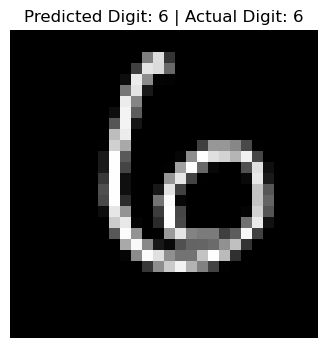

Final Model Testing
----------------------------------------
Test Image Index : 100
Predicted Digit  : 6
Actual Digit     : 6
Result           : PASS ✓
The final model predicted the digit correctly.


In [133]:
# Final Model Practical Testing

import joblib
import numpy as np
import matplotlib.pyplot as plt

# Load the final saved model
final_test_model = joblib.load("final_knn_model.pkl")

# Select one unseen test image
test_index = 100

# Get the original image and actual label
test_image = x_test[test_index]
actual_digit = y_test[test_index]

# Flatten and scale the image
test_image_scaled = test_image.reshape(1, -1) / 255.0

# Make prediction
predicted_digit = final_test_model.predict(test_image_scaled)[0]

# Display the image
plt.figure(figsize=(4, 4))
plt.imshow(test_image, cmap="gray")
plt.title(
    f"Predicted Digit: {predicted_digit} | Actual Digit: {actual_digit}"
)
plt.axis("off")
plt.show()

# Final verification
print("Final Model Testing")
print("-" * 40)
print("Test Image Index :", test_index)
print("Predicted Digit  :", predicted_digit)
print("Actual Digit     :", actual_digit)

if predicted_digit == actual_digit:
    print("Result           : PASS ✓")
    print("The final model predicted the digit correctly.")
else:
    print("Result           : FAIL ✗")
    print("The final model prediction was incorrect.")

# Final Model Practical Testing

The final saved K-Nearest Neighbors model was tested using a selected image from the held-out test dataset.

The practical testing process included:

- Loading the saved `final_knn_model.pkl` model.
- Selecting a test image from the dataset.
- Reshaping and scaling the image before prediction.
- Predicting the handwritten digit.
- Comparing the predicted digit with the actual digit.
- Displaying the image along with its predicted and actual labels.
- Verifying the result using a PASS/FAIL check.

This final test confirms that the saved model can be successfully loaded and used to make predictions on test images.

# Challenges Faced and Techniques Used

## Challenge 1 — Image Data Representation

The MNIST images were originally represented as 28 × 28 pixel arrays.

Most traditional machine learning classifiers used in this project require tabular feature representations.

### Technique Used

Each 28 × 28 image was flattened into a 784-feature vector.

### Reason

Flattening converts each image into a format that can be directly processed by traditional machine learning classification algorithms such as Logistic Regression, KNN, SVM, and Random Forest.

---

## Challenge 2 — Pixel Value Scaling

The original pixel values ranged from 0 to 255.

Different feature magnitudes can affect the behavior of machine learning algorithms.

### Technique Used

The pixel values were converted to floating-point values and normalized by dividing them by 255.

### Reason

Scaling transforms the pixel values to a range between 0 and 1, providing a consistent numerical scale for model training.

---

## Challenge 3 — Model Selection

Multiple classification algorithms were available for the handwritten digit recognition task.

### Technique Used

Four models were trained and evaluated using the same validation dataset:

- Logistic Regression
- K-Nearest Neighbors
- Linear SVM
- Random Forest

Accuracy, precision, recall, and F1 score were used for comparison.

### Reason

Comparing multiple models provides an objective way to evaluate their performance before selecting a final model.

---

## Challenge 4 — KNN Hyperparameter Selection

The performance of KNN can change depending on the number of neighbors and the weighting method.

### Technique Used

Different neighbor values were tested:

- 1
- 3
- 5
- 7

Different weighting methods were also compared:

- Distance
- Uniform

### Reason

Hyperparameter testing helps identify a configuration that provides better validation performance.

The final configuration used 3 neighbors with distance weighting.

---

## Challenge 5 — Computational Cost of KNN

KNN performs predictions by comparing observations with training data.

The prediction process therefore required additional computation, particularly when evaluating the test dataset.

### Technique Used

The KNN model was configured with `n_jobs=-1` where supported, allowing available CPU resources to be used for prediction.

### Reason

Using available processing resources helps reduce the computation time during KNN prediction.

---

## Challenge 6 — Misclassified Handwritten Digits

Some handwritten digits were incorrectly classified because different digits can have visually similar shapes or writing patterns.

### Technique Used

Error analysis was performed on the 300 incorrectly classified test images.

Misclassification pairs were calculated and the most frequent error patterns were visualized.

### Reason

Analyzing incorrect predictions helps identify the types of handwritten patterns that are difficult for the model to distinguish.

The most frequent error was Actual 4 → Predicted 9, with 25 errors.

---

## Challenge 7 — Verifying the Saved Model

After saving the final model, it was necessary to verify that the saved model could be reused correctly.

### Technique Used

The final KNN model was saved using `joblib`, loaded again, and its predictions were compared with the original model predictions.

### Reason

This verifies that the saved model can be loaded and used for future predictions without changing its prediction behavior.

## Project Conclusion

The handwritten digit recognition project successfully applied machine learning classification techniques to recognize digits from handwritten images.

Four classification algorithms were evaluated, and K-Nearest Neighbors achieved the highest validation accuracy among the tested models.

The final KNN model used 3 neighbors with distance weighting.

The model achieved 97% accuracy on the separate test dataset, correctly classifying 9,700 out of 10,000 test images.

Error analysis showed that most incorrect predictions occurred between visually similar handwritten digits.

The final model was saved as `final_knn_model.pkl`, allowing it to be loaded and reused for future predictions.

Overall, the project demonstrated the complete machine learning workflow, including data preprocessing, exploratory analysis, model development, model comparison, hyperparameter tuning, final evaluation, error analysis, and model saving.